In [1]:
# =====================================================
# ELASTIC NET REGRESSION - STEP 1
# Load and Verify Reliance Stock Dataset
# =====================================================

import os
import numpy as np
import pandas as pd

project_path = (
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

data_path = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "Reliance_Prepared_Data_2017_2026.csv"
)

if not os.path.exists(data_path):
    raise FileNotFoundError(
        f"Dataset not found at:\n{data_path}"
    )

print("Dataset file found successfully!")

df = pd.read_csv(data_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

if "Date" in df.columns:
    dates = pd.to_datetime(df["Date"], errors="coerce")

    print("Invalid dates:", dates.isna().sum())

    print(
        "Duplicate dates:",
        dates.duplicated().sum()
    )

    print(
        "Date range:",
        dates.min(),
        "to",
        dates.max()
    )
else:
    print("WARNING: Date column is missing.")

numeric_df = df.select_dtypes(include=[np.number])

print("\nInfinite values in numerical columns:")
print(
    pd.Series(
        np.isinf(numeric_df).sum(),
        index=numeric_df.columns
    )
)

required_columns = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Next_Day_Close"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("\nRequired-column verification:")

if not missing_columns:
    print("All required columns are present.")
else:
    print("Missing columns:", missing_columns)

print("\nElastic Net Step 1 verification completed.")


Dataset file found successfully!

Dataset loaded successfully!
Dataset shape: (2400, 7)

First five rows:


,Date,Open,High,Low,Close,Volume,Next_Day_Close
0,2017-01-02,247.784164,249.155670,245.121170,248.035614,7097888,249.018509
1,2017-01-03,249.121384,250.755753,247.121277,249.018509,6434204,243.932541
2,2017-01-04,249.818558,249.841415,243.281082,243.932541,10392483,246.275513
3,2017-01-05,244.812592,246.846970,244.298279,246.275513,8734164,245.715485
4,2017-01-06,245.544052,248.012756,245.292603,245.715485,7845839,246.344086



Last five rows:


,Date,Open,High,Low,Close,Volume,Next_Day_Close
2395,2026-09-10,1278.500000,1285.300049,1266.300049,1274.000000,9296079,1257.500000
2396,2026-09-11,1267.000000,1267.400024,1253.000000,1257.500000,8777736,1235.300049
2397,2026-09-15,1252.500000,1259.400024,1235.300049,1235.300049,13754376,1240.000000
2398,2026-09-16,1243.000000,1255.000000,1240.000000,1240.000000,10023997,1243.900024
2399,2026-09-17,1244.800049,1253.400024,1238.500000,1243.900024,7752895,1226.400024



Column names:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Next_Day_Close']

Data types:
Date                  str
Open              float64
High              float64
Low               float64
Close             float64
Volume              int64
Next_Day_Close    float64
dtype: object

Missing values in each column:
Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
Next_Day_Close    0
dtype: int64

Duplicate rows: 0
Invalid dates: 0
Duplicate dates: 0
Date range: 2017-01-02 00:00:00 to 2026-09-17 00:00:00

Infinite values in numerical columns:
Open              0
High              0
Low               0
Close             0
Volume            0
Next_Day_Close    0
dtype: int64

Required-column verification:
All required columns are present.

Elastic Net Step 1 verification completed.


In [2]:
# =====================================================
# ELASTIC NET REGRESSION - STEP 2
# Prepare Features (X) and Target (y)
# =====================================================

import pandas as pd

feature_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

target_column = "Next_Day_Close"

required_columns = feature_columns + [target_column]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

X = df[feature_columns].copy()
y = df[target_column].copy()

print("ELASTIC NET: FEATURES AND TARGET PREPARED")
print("=" * 45)

print("\nInput features (X):")
print(feature_columns)

print("\nTarget variable (y):")
print(target_column)

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFirst five feature rows:")
display(X.head())

print("\nFirst five target values:")
display(y.head())

print("\nFeature data types:")
print(X.dtypes)

print("\nTarget data type:")
print(y.dtype)

print("\nMissing values in features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

assert X.isnull().sum().sum() == 0, \
    "Feature matrix contains missing values."

assert y.isnull().sum() == 0, \
    "Target contains missing values."

assert X.shape[0] == y.shape[0], \
    "Feature and target row counts do not match."

print("\nElastic Net Step 2 completed successfully!")


ELASTIC NET: FEATURES AND TARGET PREPARED

Input features (X):
['Open', 'High', 'Low', 'Close', 'Volume']

Target variable (y):
Next_Day_Close

Feature matrix shape: (2400, 5)
Target vector shape: (2400,)

First five feature rows:


,Open,High,Low,Close,Volume
0,247.784164,249.155670,245.121170,248.035614,7097888
1,249.121384,250.755753,247.121277,249.018509,6434204
2,249.818558,249.841415,243.281082,243.932541,10392483
3,244.812592,246.846970,244.298279,246.275513,8734164
4,245.544052,248.012756,245.292603,245.715485,7845839



First five target values:


0    249.018509
1    243.932541
2    246.275513
3    245.715485
4    246.344086
Name: Next_Day_Close, dtype: float64


Feature data types:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

Target data type:
float64

Missing values in features:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Missing values in target:
0

Elastic Net Step 2 completed successfully!


In [3]:
# =====================================================
# ELASTIC NET REGRESSION - STEP 3
# Chronological Train-Test Split (80:20)
# =====================================================

# Calculate the split index
split_index = int(len(df) * 0.80)

# Exclude the boundary row to avoid target leakage
train_end = split_index - 1

# Create training and testing datasets
X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_test = X.iloc[split_index:].copy()
y_test = y.iloc[split_index:].copy()

# Extract corresponding dates
train_dates = df["Date"].iloc[:train_end]
test_dates = df["Date"].iloc[split_index:]

# Display split information
print("ELASTIC NET: TRAIN-TEST SPLIT SUMMARY")
print("=" * 50)

print("Total dataset rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining date range:")
print(train_dates.min(), "to", train_dates.max())

print("\nTesting date range:")
print(test_dates.min(), "to", test_dates.max())

print("\nTraining feature shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("\nTesting feature shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

# Verify split correctness
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert train_dates.max() < test_dates.min()

print("\nElastic Net Step 3 completed successfully!")


ELASTIC NET: TRAIN-TEST SPLIT SUMMARY
Total dataset rows: 2400
Training rows: 1919
Testing rows: 480

Training date range:
2017-01-02 to 2024-10-09

Testing date range:
2024-10-11 to 2026-09-17

Training feature shape: (1919, 5)
Training target shape: (1919,)

Testing feature shape: (480, 5)
Testing target shape: (480,)

Elastic Net Step 3 completed successfully!


STEP 4: ELASTIC NET REGRESSION MODEL TRAINING AND EVALUATION

1. Output directory created/verified.
   Results will be saved in: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net

2. Elastic Net model initialized.
   StandardScaler: scales input features.
   Alpha: 0.1
   L1 ratio: 0.5
   L1 ratio 0.5 combines L1 and L2 regularization.

3. Model training completed successfully.
   Training rows used: 1919
   Input features used: ['Open', 'High', 'Low', 'Close', 'Volume']

4. Predictions generated successfully.
   Training predictions: 1919
   Testing predictions: 480

5. Evaluation metrics configured:
   MAE      : Mean Absolute Error.
   RMSE     : Root Mean Squared Error.
   R-squared: Measures explained variation.
   MAPE     : Mean Absolute Percentage Error.
   Accuracy : 100 - MAPE, a custom regression indicator.

6. ELASTIC NET MODEL EVALUATION RESULTS


,Dataset,MAE,RMSE,R2,MAPE_Percentage,Prediction_Accuracy_Percentage
0,Training,12.3302,16.9492,0.9978,1.6068,98.3932
1,Testing,15.4166,20.3840,0.9546,1.1334,98.8666



7. Evaluation metrics saved successfully.
   File: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\Reliance_Elastic_Net_Evaluation_Metrics.csv

8. Test predictions saved successfully.
   File: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\Reliance_Elastic_Net_Test_Predictions.csv


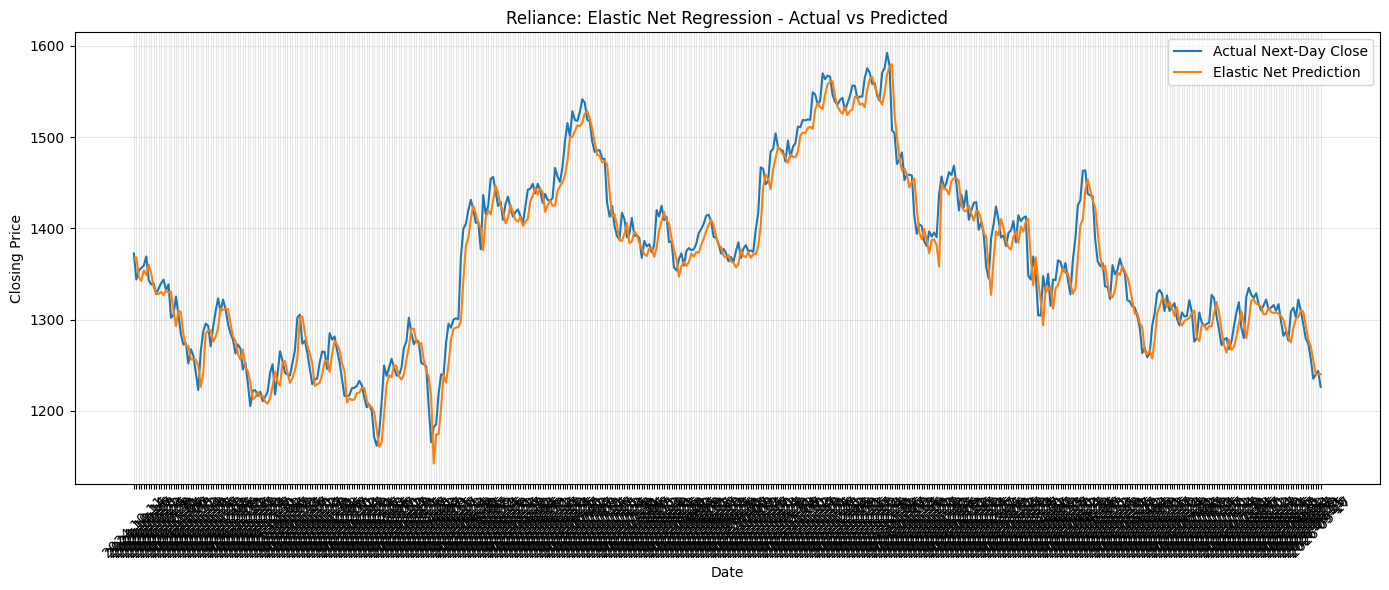


9. Actual vs Predicted graph generated and saved.
   File: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\Reliance_Elastic_Net_Actual_vs_Predicted.png

ELASTIC NET STEP 4 COMPLETED SUCCESSFULLY
What happened in this step?
- Elastic Net was trained on historical Reliance stock data.
- StandardScaler scaled the input features.
- The model predicted Next_Day_Close for training and testing data.
- MAE, RMSE, R-squared, MAPE and a custom regression indicator were calculated.
- Evaluation metrics, test predictions and the graph were saved.

Important interpretation:
- Lower MAE, RMSE and MAPE generally indicate smaller errors.
- Higher R-squared generally indicates a better fit.
- Prediction indicator = 100 - MAPE; it is not classification accuracy.
- This initial model uses alpha=0.1 and l1_ratio=0.5.
- These parameters have not been tuned in this step.

All Elastic Net Step 4 outputs have been generated.


In [4]:
# =====================================================
# ELASTIC NET REGRESSION - STEP 4
# Model Training and Evaluation
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# 1. Create output directory
output_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "elastic_net"
)

os.makedirs(output_dir, exist_ok=True)

print("=" * 65)
print("STEP 4: ELASTIC NET REGRESSION MODEL TRAINING AND EVALUATION")
print("=" * 65)

print("\n1. Output directory created/verified.")
print("   Results will be saved in:", output_dir)

# 2. Initialize Elastic Net pipeline
elastic_net_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=10000,
        random_state=42
    ))
])

print("\n2. Elastic Net model initialized.")
print("   StandardScaler: scales input features.")
print("   Alpha:", 0.1)
print("   L1 ratio:", 0.5)
print("   L1 ratio 0.5 combines L1 and L2 regularization.")

# 3. Train the model
elastic_net_model.fit(X_train, y_train)

print("\n3. Model training completed successfully.")
print("   Training rows used:", len(X_train))
print("   Input features used:", list(X_train.columns))

# 4. Generate predictions
y_train_pred = elastic_net_model.predict(X_train)
y_test_pred = elastic_net_model.predict(X_test)

print("\n4. Predictions generated successfully.")
print("   Training predictions:", len(y_train_pred))
print("   Testing predictions:", len(y_test_pred))

# 5. Define evaluation function
def evaluate_model(actual, predicted):
    actual_array = np.asarray(actual, dtype=float)
    predicted_array = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(
        actual_array,
        predicted_array
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_array,
            predicted_array
        )
    )

    r2 = r2_score(
        actual_array,
        predicted_array
    )

    # MAPE is undefined when actual values are zero.
    nonzero_mask = actual_array != 0

    if nonzero_mask.any():
        mape = mean_absolute_percentage_error(
            actual_array[nonzero_mask],
            predicted_array[nonzero_mask]
        ) * 100

        prediction_accuracy = 100 - mape
    else:
        mape = np.nan
        prediction_accuracy = np.nan

    return mae, rmse, r2, mape, prediction_accuracy

print("\n5. Evaluation metrics configured:")
print("   MAE      : Mean Absolute Error.")
print("   RMSE     : Root Mean Squared Error.")
print("   R-squared: Measures explained variation.")
print("   MAPE     : Mean Absolute Percentage Error.")
print("   Accuracy : 100 - MAPE, a custom regression indicator.")

# 6. Evaluate training and testing performance
(
    train_mae,
    train_rmse,
    train_r2,
    train_mape,
    train_accuracy
) = evaluate_model(y_train, y_train_pred)

(
    test_mae,
    test_rmse,
    test_r2,
    test_mape,
    test_accuracy
) = evaluate_model(y_test, y_test_pred)

# 7. Create metrics table
metrics_df = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse],
    "R2": [train_r2, test_r2],
    "MAPE_Percentage": [train_mape, test_mape],
    "Prediction_Accuracy_Percentage": [
        train_accuracy,
        test_accuracy
    ]
})

print("\n6. ELASTIC NET MODEL EVALUATION RESULTS")
print("=" * 80)
display(metrics_df.round(4))

# 8. Save evaluation metrics
metrics_path = os.path.join(
    output_dir,
    "Reliance_Elastic_Net_Evaluation_Metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

print("\n7. Evaluation metrics saved successfully.")
print("   File:", metrics_path)

# 9. Save test predictions
predictions_df = pd.DataFrame({
    "Date": df["Date"].iloc[split_index:].values,
    "Actual_Next_Day_Close": y_test.values,
    "Predicted_Next_Day_Close": y_test_pred
})

predictions_path = os.path.join(
    output_dir,
    "Reliance_Elastic_Net_Test_Predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

print("\n8. Test predictions saved successfully.")
print("   File:", predictions_path)

# 10. Plot actual vs predicted values
plt.figure(figsize=(14, 6))

plt.plot(
    predictions_df["Date"],
    predictions_df["Actual_Next_Day_Close"],
    label="Actual Next-Day Close"
)

plt.plot(
    predictions_df["Date"],
    predictions_df["Predicted_Next_Day_Close"],
    label="Elastic Net Prediction"
)

plt.title(
    "Reliance: Elastic Net Regression - Actual vs Predicted"
)
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

graph_path = os.path.join(
    output_dir,
    "Reliance_Elastic_Net_Actual_vs_Predicted.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n9. Actual vs Predicted graph generated and saved.")
print("   File:", graph_path)

# 11. Final program summary
print("\n" + "=" * 65)
print("ELASTIC NET STEP 4 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("What happened in this step?")
print("- Elastic Net was trained on historical Reliance stock data.")
print("- StandardScaler scaled the input features.")
print("- The model predicted Next_Day_Close for training and testing data.")
print("- MAE, RMSE, R-squared, MAPE and a custom regression indicator were calculated.")
print("- Evaluation metrics, test predictions and the graph were saved.")

print("\nImportant interpretation:")
print("- Lower MAE, RMSE and MAPE generally indicate smaller errors.")
print("- Higher R-squared generally indicates a better fit.")
print("- Prediction indicator = 100 - MAPE; it is not classification accuracy.")
print("- This initial model uses alpha=0.1 and l1_ratio=0.5.")
print("- These parameters have not been tuned in this step.")

print("\nAll Elastic Net Step 4 outputs have been generated.")


RELIANCE INDUSTRIES - ELASTIC NET REGRESSION
STEP 5: HYPERPARAMETER TUNING

OBJECTIVE
Find the Elastic Net hyperparameters that minimize
the mean chronological cross-validation MAE.

OUTPUT DIRECTORY
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning

HYPERPARAMETER SEARCH SPACE
Alpha values: [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
L1 ratio values: [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1.0]
Total combinations: 49

CROSS-VALIDATION CONFIGURATION
Validation method: TimeSeriesSplit
Number of folds: 5
Optimization metric: MAE
Tuning data: Training set only
Held-out test data used during tuning: No

Running hyperparameter search...
Fitting 5 folds for each of 49 candidates, totalling 245 fits

BEST HYPERPARAMETERS
Best alpha: 0.1
Best l1_ratio: 1
Best mean CV MAE: 11.5983
Number of configurations tested: 49
Number of CV folds: 5

TOP 10 HYPERPARAMETER CONFIGURATIONS
Lower Mean_CV_MAE is better.


,CV_Rank,Alpha,L1_Ratio,Mean_CV_MAE,Std_CV_MAE,Mean_Training_MAE
0,1,0.1000,1.00,11.5983,2.2363,7.2132
1,2,0.0010,0.95,11.6202,2.2669,7.1940
2,3,0.0001,1.00,11.6219,2.2694,7.1902
3,4,0.0001,0.95,11.6219,2.2694,7.1904
4,5,0.0001,0.90,11.6220,2.2697,7.1907
5,6,0.0001,0.75,11.6221,2.2703,7.1918
6,7,0.0010,0.90,11.6226,2.2635,7.2007
7,8,0.0001,0.50,11.6230,2.2699,7.1945
8,9,0.0001,0.25,11.6242,2.2684,7.1977
9,10,0.0010,1.00,11.6250,2.2716,7.1904


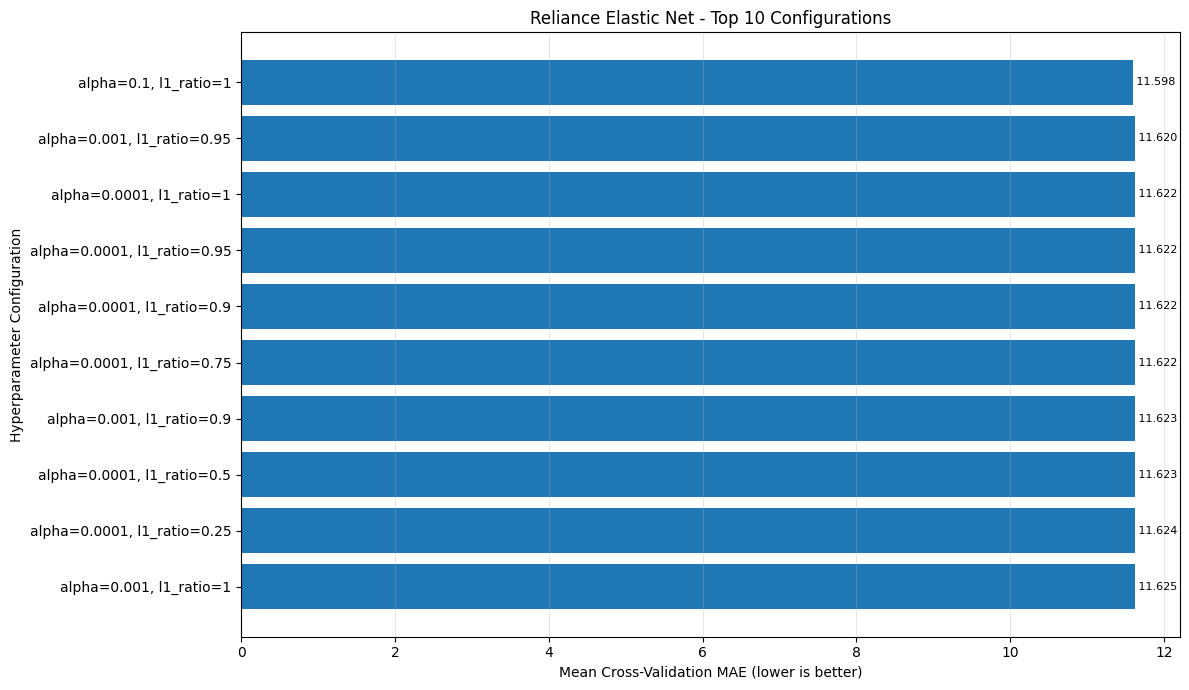


SAVED OUTPUT FILES
1. All CV results:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\Reliance_Elastic_Net_CV_Results.csv

2. Best parameter summary:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\Reliance_Elastic_Net_Best_Parameters.csv

3. Top 10 comparison graph:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\Reliance_Elastic_Net_Top_10_Configurations.png

INTERPRETATION
The best alpha selected by cross-validation is 0.1.
The best l1_ratio selected by cross-validation is 1.
The lowest mean cross-validation MAE is 11.5983.
This MAE represents the average absolute prediction error across the chronological validation folds, in the target's units.
The standard deviation of CV MAE helps indicate how much validation error varies across folds.
The held-out test dataset was not used to select these parame

In [7]:
# ELASTIC NET REGRESSION - STEP 5
# Hyperparameter Tuning Using TimeSeriesSplit
# =====================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tuning_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "elastic_net",
    "hyperparameter_tuning"
)

os.makedirs(tuning_dir, exist_ok=True)

print("=" * 75)
print("RELIANCE INDUSTRIES - ELASTIC NET REGRESSION")
print("STEP 5: HYPERPARAMETER TUNING")
print("=" * 75)

print("\nOBJECTIVE")
print("Find the Elastic Net hyperparameters that minimize")
print("the mean chronological cross-validation MAE.")

print("\nOUTPUT DIRECTORY")
print(tuning_dir)

elastic_net_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(
        max_iter=50000,
        random_state=42
    ))
])

param_grid = {
    "model__alpha": [
        0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0
    ],
    "model__l1_ratio": [
        0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1.0
    ]
}

total_combinations = (
    len(param_grid["model__alpha"]) *
    len(param_grid["model__l1_ratio"])
)

print("\nHYPERPARAMETER SEARCH SPACE")
print("Alpha values:", param_grid["model__alpha"])
print("L1 ratio values:", param_grid["model__l1_ratio"])
print("Total combinations:", total_combinations)

tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=elastic_net_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    error_score="raise"
)

print("\nCROSS-VALIDATION CONFIGURATION")
print("Validation method: TimeSeriesSplit")
print("Number of folds:", tscv.n_splits)
print("Optimization metric: MAE")
print("Tuning data: Training set only")
print("Held-out test data used during tuning: No")

print("\nRunning hyperparameter search...")

grid_search.fit(X_train, y_train)

best_alpha = float(
    grid_search.best_params_["model__alpha"]
)

best_l1_ratio = float(
    grid_search.best_params_["model__l1_ratio"]
)

best_cv_mae = float(-grid_search.best_score_)

best_elastic_net_model = grid_search.best_estimator_

print("\n" + "=" * 75)
print("BEST HYPERPARAMETERS")
print("=" * 75)

print(f"Best alpha: {best_alpha:g}")
print(f"Best l1_ratio: {best_l1_ratio:g}")
print(f"Best mean CV MAE: {best_cv_mae:.4f}")
print("Number of configurations tested:", total_combinations)
print("Number of CV folds:", tscv.n_splits)

cv_results_df = pd.DataFrame(grid_search.cv_results_)

cv_results_df["Mean_CV_MAE"] = (
    -cv_results_df["mean_test_score"]
)

cv_results_df["Std_CV_MAE"] = (
    cv_results_df["std_test_score"]
)

cv_results_df["Mean_Training_MAE"] = (
    -cv_results_df["mean_train_score"]
)

cv_results_df["Alpha"] = (
    cv_results_df["param_model__alpha"].astype(float)
)

cv_results_df["L1_Ratio"] = (
    cv_results_df["param_model__l1_ratio"].astype(float)
)

cv_results_df = cv_results_df.sort_values(
    by="Mean_CV_MAE",
    ascending=True
).reset_index(drop=True)

cv_results_df.insert(
    0,
    "CV_Rank",
    np.arange(1, len(cv_results_df) + 1)
)

display_columns = [
    "CV_Rank",
    "Alpha",
    "L1_Ratio",
    "Mean_CV_MAE",
    "Std_CV_MAE",
    "Mean_Training_MAE"
]

print("\n" + "=" * 75)
print("TOP 10 HYPERPARAMETER CONFIGURATIONS")
print("Lower Mean_CV_MAE is better.")
print("=" * 75)

top_10 = cv_results_df[display_columns].head(10).round(4)
display(top_10)

cv_results_path = os.path.join(
    tuning_dir,
    "Reliance_Elastic_Net_CV_Results.csv"
)

cv_results_df.to_csv(cv_results_path, index=False)

best_params_df = pd.DataFrame({
    "Parameter": [
        "Best_Alpha",
        "Best_L1_Ratio",
        "Best_CV_MAE",
        "Number_of_Combinations",
        "Number_of_CV_Folds"
    ],
    "Value": [
        best_alpha,
        best_l1_ratio,
        best_cv_mae,
        total_combinations,
        tscv.n_splits
    ]
})

best_params_path = os.path.join(
    tuning_dir,
    "Reliance_Elastic_Net_Best_Parameters.csv"
)

best_params_df.to_csv(best_params_path, index=False)

top_10_plot = cv_results_df.head(10).copy()

top_10_plot["Configuration"] = (
    "alpha=" + top_10_plot["Alpha"].map(lambda x: f"{x:g}") +
    ", l1_ratio=" +
    top_10_plot["L1_Ratio"].map(lambda x: f"{x:g}")
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_plot["Configuration"].iloc[::-1],
    top_10_plot["Mean_CV_MAE"].iloc[::-1]
)

plt.xlabel("Mean Cross-Validation MAE (lower is better)")
plt.ylabel("Hyperparameter Configuration")
plt.title("Reliance Elastic Net - Top 10 Configurations")
plt.grid(axis="x", alpha=0.3)

for bar in bars:
    value = bar.get_width()
    plt.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f" {value:.3f}",
        va="center",
        fontsize=8
    )

plt.tight_layout()

plot_path = os.path.join(
    tuning_dir,
    "Reliance_Elastic_Net_Top_10_Configurations.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 75)
print("SAVED OUTPUT FILES")
print("=" * 75)
print("1. All CV results:")
print(cv_results_path)
print("\n2. Best parameter summary:")
print(best_params_path)
print("\n3. Top 10 comparison graph:")
print(plot_path)

print("\n" + "=" * 75)
print("INTERPRETATION")
print("=" * 75)

print(
    f"The best alpha selected by cross-validation is {best_alpha:g}."
)
print(
    f"The best l1_ratio selected by cross-validation is "
    f"{best_l1_ratio:g}."
)
print(
    f"The lowest mean cross-validation MAE is {best_cv_mae:.4f}."
)
print(
    "This MAE represents the average absolute prediction error "
    "across the chronological validation folds, in the target's units."
)
print(
    "The standard deviation of CV MAE helps indicate how much "
    "validation error varies across folds."
)
print(
    "The held-out test dataset was not used to select these parameters."
)

print("\n" + "=" * 75)
print("CONCLUSION")
print("=" * 75)

print(
    "GridSearchCV has selected the best-performing configuration "
    "among the tested Elastic Net hyperparameter combinations "
    "according to mean chronological cross-validation MAE."
)
print(
    "The tuned model is stored in the variable "
    "'best_elastic_net_model'."
)
print(
    "Its final performance must be assessed separately on X_test "
    "and y_test and compared with the original Elastic Net model."
)
print(
    "Hyperparameter tuning alone does not establish that the model "
    "is more accurate on unseen test data."
)

print("\nSTEP 5 COMPLETED SUCCESSFULLY")
print("=" * 75)


RELIANCE INDUSTRIES - ELASTIC NET REGRESSION
STEP 6: TUNED MODEL TEST EVALUATION

TEST DATASET SUMMARY
-------------------------------------------------------
Number of test observations: 480
Input features: ['Open', 'High', 'Low', 'Close', 'Volume']
Selected alpha: 0.1
Selected l1_ratio: 1.0

TUNED ELASTIC NET - TEST RESULTS
-------------------------------------------------------
MAE: 13.2948
RMSE: 17.8140
R-squared (R²): 0.9653
MAPE: 0.9819%
Custom 100 - MAPE indicator: 99.0181%
Up/Down Directional Accuracy: 51.67%

FIRST 10 TEST PREDICTIONS
---------------------------------------------------------------------------


C:\Users\Shilpi Chouhan\AppData\Local\Temp\ipykernel_19112\3897979320.py:201: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(predictions_df.head(10).round(4))


,Date,Current_Close,Actual_Next_Day_Close,Predicted_Next_Day_Close,Absolute_Error,Percentage_Error,Actual_Direction,Predicted_Direction,Direction_Correct
0,2024-10-11,1372.100,1372.525,1373.5093,0.9843,0.0717,Up,Up,True
1,2024-10-14,1372.525,1344.025,1373.7693,29.7442,2.2131,Down,Up,False
2,2024-10-15,1344.025,1354.075,1346.8545,7.2205,0.5332,Up,Up,True
3,2024-10-16,1354.075,1356.425,1353.3137,3.1113,0.2294,Up,Down,False
4,2024-10-17,1356.425,1359.300,1357.9090,1.3911,0.1023,Up,Up,True
5,2024-10-18,1359.300,1369.200,1357.9435,11.2564,0.8221,Up,Down,False
6,2024-10-21,1369.200,1343.350,1369.0271,25.6771,1.9114,Down,Down,True
7,2024-10-22,1343.350,1338.525,1345.7599,7.2349,0.5405,Down,Up,False
8,2024-10-23,1338.525,1339.800,1340.4550,0.6549,0.0489,Up,Up,True
9,2024-10-24,1339.800,1327.850,1338.8684,11.0184,0.8298,Down,Down,True



ORIGINAL VS TUNED COMPARISON
-------------------------------------------------------
A compatible original Step 4 test-metrics file was not found or its format could not be recognized.
The tuned model results have been saved. Compare them with the original Step 4 test metrics before claiming improvement.


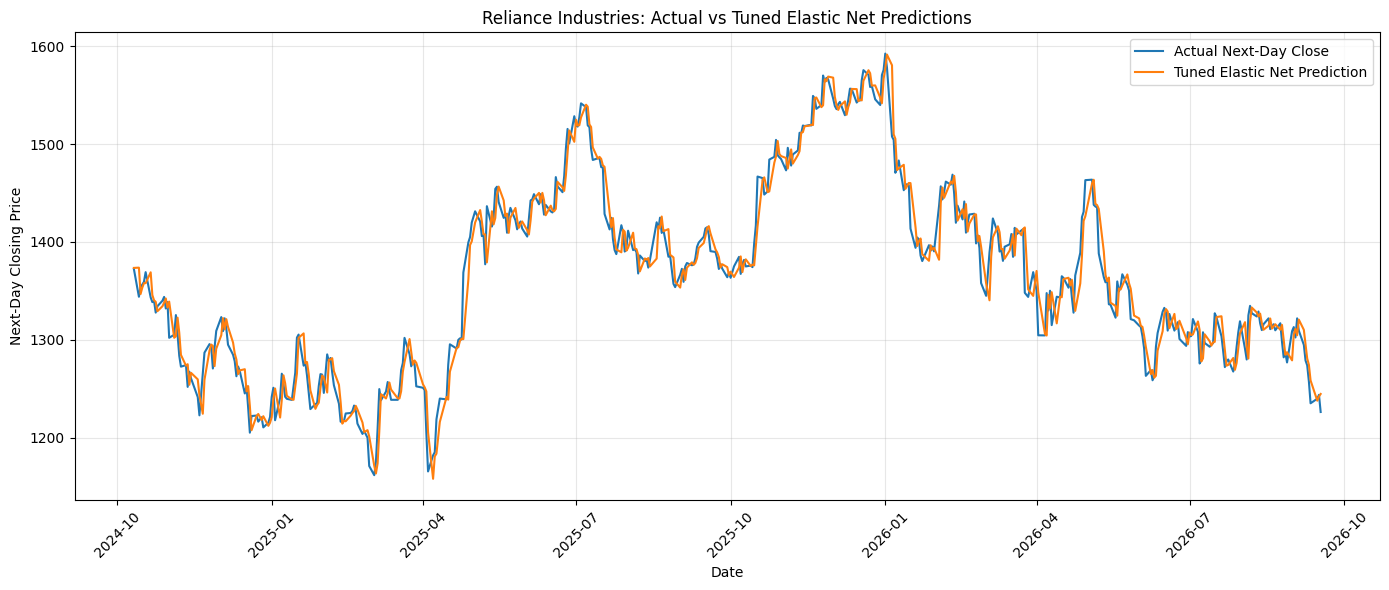


SAVED OUTPUT FILES
---------------------------------------------------------------------------
Test metrics: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\Reliance_Elastic_Net_Tuned_Test_Metrics.csv
Test predictions: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\Reliance_Elastic_Net_Tuned_Test_Predictions.csv
Comparison graph: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\Reliance_Elastic_Net_Tuned_Actual_vs_Predicted.png

INTERPRETATION
---------------------------------------------------------------------------
Test MAE: 13.2948 - average absolute prediction error.
Test RMSE: 17.8140 - penalizes larger prediction errors more heavily than MAE.
Test R²: 0.9653 - measures performance relative to predicting the test-set mean.
Test MAPE: 0.9819% - average absolute percentage error for nonzero actual 

In [10]:
# =====================================================
# Step 6 — Test Evaluation of Tuned Elastic Net Model
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

evaluation_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "elastic_net",
    "hyperparameter_tuning"
)

os.makedirs(evaluation_dir, exist_ok=True)

print("=" * 75)
print("RELIANCE INDUSTRIES - ELASTIC NET REGRESSION")
print("STEP 6: TUNED MODEL TEST EVALUATION")
print("=" * 75)

# Generate predictions using the tuned model
y_test_actual = np.asarray(y_test).reshape(-1)

y_test_predicted = np.asarray(
    best_elastic_net_model.predict(X_test)
).reshape(-1)

if len(y_test_actual) != len(y_test_predicted):
    raise ValueError("Actual and predicted values have different lengths.")

# Calculate regression metrics
test_mae = mean_absolute_error(
    y_test_actual, y_test_predicted
)

test_rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_test_predicted)
)

test_r2 = r2_score(
    y_test_actual, y_test_predicted
)

nonzero_mask = y_test_actual != 0

if np.any(nonzero_mask):
    test_mape = np.mean(
        np.abs(
            (
                y_test_actual[nonzero_mask]
                - y_test_predicted[nonzero_mask]
            ) / y_test_actual[nonzero_mask]
        )
    ) * 100
else:
    test_mape = np.nan

# Custom indicator only; not standard regression accuracy
custom_mape_indicator = (
    100 - test_mape
    if np.isfinite(test_mape)
    else np.nan
)

# Calculate Up/Down Directional Accuracy
# Compares price movement relative to the current Close.
if "Close" not in X_test.columns:
    raise ValueError(
        "The Close feature is required to calculate "
        "Up/Down Directional Accuracy."
    )

current_close = np.asarray(
    X_test["Close"]
).reshape(-1)

if len(current_close) != len(y_test_actual):
    raise ValueError(
        "Current closing prices and test targets have different lengths."
    )

actual_direction = np.sign(
    y_test_actual - current_close
)

predicted_direction = np.sign(
    y_test_predicted - current_close
)

directional_accuracy = np.mean(
    actual_direction == predicted_direction
) * 100

# Display test dataset information
best_model = best_elastic_net_model.named_steps["model"]

print("\nTEST DATASET SUMMARY")
print("-" * 55)
print("Number of test observations:", len(y_test_actual))
print("Input features:", list(X_test.columns))
print("Selected alpha:", best_model.alpha)
print("Selected l1_ratio:", best_model.l1_ratio)

# Display tuned model metrics
print("\nTUNED ELASTIC NET - TEST RESULTS")
print("-" * 55)
print(f"MAE: {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R-squared (R²): {test_r2:.4f}")
print(f"MAPE: {test_mape:.4f}%")
print(
    "Custom 100 - MAPE indicator: "
    f"{custom_mape_indicator:.4f}%"
)
print(
    "Up/Down Directional Accuracy: "
    f"{directional_accuracy:.2f}%"
)

# Prepare dates for test predictions
if "Date" in df.columns:
    test_dates = pd.to_datetime(
        df["Date"].iloc[split_index:]
    ).reset_index(drop=True)
else:
    test_dates = pd.RangeIndex(
        start=0,
        stop=len(y_test_actual),
        name="Test_Row"
    )

if len(test_dates) != len(y_test_actual):
    raise ValueError(
        "Test dates and y_test have different lengths. "
        "Check the chronological split and date alignment."
    )

# Create actual-versus-predicted results
predictions_df = pd.DataFrame({
    "Date": test_dates,
    "Current_Close": current_close,
    "Actual_Next_Day_Close": y_test_actual,
    "Predicted_Next_Day_Close": y_test_predicted
})

predictions_df["Absolute_Error"] = np.abs(
    predictions_df["Actual_Next_Day_Close"]
    - predictions_df["Predicted_Next_Day_Close"]
)

predictions_df["Percentage_Error"] = np.where(
    predictions_df["Actual_Next_Day_Close"] != 0,
    predictions_df["Absolute_Error"]
    / np.abs(predictions_df["Actual_Next_Day_Close"]) * 100,
    np.nan
)

# Include actual and predicted price directions
predictions_df["Actual_Direction"] = np.where(
    predictions_df["Actual_Next_Day_Close"]
    > predictions_df["Current_Close"],
    "Up",
    np.where(
        predictions_df["Actual_Next_Day_Close"]
        < predictions_df["Current_Close"],
        "Down",
        "No Change"
    )
)

predictions_df["Predicted_Direction"] = np.where(
    predictions_df["Predicted_Next_Day_Close"]
    > predictions_df["Current_Close"],
    "Up",
    np.where(
        predictions_df["Predicted_Next_Day_Close"]
        < predictions_df["Current_Close"],
        "Down",
        "No Change"
    )
)

predictions_df["Direction_Correct"] = (
    predictions_df["Actual_Direction"]
    == predictions_df["Predicted_Direction"]
)

print("\nFIRST 10 TEST PREDICTIONS")
print("-" * 75)
display(predictions_df.head(10).round(4))

# Save prediction results
predictions_path = os.path.join(
    evaluation_dir,
    "Reliance_Elastic_Net_Tuned_Test_Predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

# Save tuned model metrics
metrics_df = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2",
        "MAPE_Percent",
        "Custom_100_Minus_MAPE_Percent",
        "Directional_Accuracy_Percent"
    ],
    "Tuned_Test_Value": [
        test_mae,
        test_rmse,
        test_r2,
        test_mape,
        custom_mape_indicator,
        directional_accuracy
    ]
})

metrics_path = os.path.join(
    evaluation_dir,
    "Reliance_Elastic_Net_Tuned_Test_Metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

# Compare with the original Elastic Net model from Step 4
original_metrics_path = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "elastic_net",
    "Reliance_Elastic_Net_Evaluation_Metrics.csv"
)

comparison_df = None

if os.path.exists(original_metrics_path):
    original_df = pd.read_csv(original_metrics_path)

    metric_column = next(
        (
            col for col in original_df.columns
            if col.strip().lower() in ["metric", "metrics"]
        ),
        None
    )

    if metric_column is not None:
        original_df[metric_column] = (
            original_df[metric_column].astype(str).str.strip()
        )

        test_column = next(
            (
                col for col in original_df.columns
                if "test" in col.lower()
                and any(
                    word in col.lower()
                    for word in ["value", "score", "result"]
                )
            ),
            None
        )

        if test_column is not None:
            original_test = original_df.set_index(
                metric_column
            )[test_column]

            original_metric_map = {
                "MAE": "MAE",
                "RMSE": "RMSE",
                "R2": "R2",
                "MAPE": "MAPE"
            }

            original_values = {}

            for standard_name, saved_name in original_metric_map.items():
                normalized_index = (
                    original_test.index.astype(str)
                    .str.lower()
                    .str.replace("-", "_", regex=False)
                    .str.replace(" ", "_", regex=False)
                )

                matching_rows = original_test.index[
                    normalized_index.str.startswith(saved_name.lower())
                ]

                if len(matching_rows) > 0:
                    value = original_test.loc[matching_rows[0]]

                    if isinstance(value, pd.Series):
                        value = value.iloc[0]

                    original_values[standard_name] = float(value)

            if all(
                name in original_values
                for name in ["MAE", "RMSE", "R2", "MAPE"]
            ):
                comparison_df = pd.DataFrame({
                    "Metric": ["MAE", "RMSE", "R2", "MAPE"],
                    "Original_Elastic_Net_Test": [
                        original_values["MAE"],
                        original_values["RMSE"],
                        original_values["R2"],
                        original_values["MAPE"]
                    ],
                    "Tuned_Elastic_Net_Test": [
                        test_mae,
                        test_rmse,
                        test_r2,
                        test_mape
                    ]
                })

                comparison_df["Change_After_Tuning"] = (
                    comparison_df["Tuned_Elastic_Net_Test"]
                    - comparison_df["Original_Elastic_Net_Test"]
                )

                comparison_path = os.path.join(
                    evaluation_dir,
                    "Reliance_Elastic_Net_Original_vs_Tuned.csv"
                )

                comparison_df.to_csv(
                    comparison_path,
                    index=False
                )

                print("\nORIGINAL VS TUNED MODEL COMPARISON")
                print("-" * 75)
                display(comparison_df.round(4))

                print(
                    "\nFor MAE, RMSE and MAPE, lower values are better. "
                    "For R², higher values are generally better."
                )

                print("\nCOMPARISON INTERPRETATION")

                original_mae = original_values["MAE"]
                original_rmse = original_values["RMSE"]
                original_r2 = original_values["R2"]
                original_mape = original_values["MAPE"]

                print(
                    f"MAE change: {test_mae - original_mae:+.4f}"
                )
                print(
                    f"RMSE change: {test_rmse - original_rmse:+.4f}"
                )
                print(
                    f"R² change: {test_r2 - original_r2:+.4f}"
                )
                print(
                    f"MAPE change: {test_mape - original_mape:+.4f} "
                    "percentage points"
                )

                if (
                    test_mae < original_mae
                    and test_rmse < original_rmse
                    and test_r2 > original_r2
                    and test_mape < original_mape
                ):
                    print(
                        "The tuned model improved all four regression "
                        "metrics on the test dataset."
                    )
                elif (
                    test_mae > original_mae
                    and test_rmse > original_rmse
                    and test_r2 < original_r2
                    and test_mape > original_mape
                ):
                    print(
                        "The tuned model performed worse on all four "
                        "regression metrics on the test dataset."
                    )
                else:
                    print(
                        "The results are mixed. Evaluate all metrics "
                        "together before deciding which model is better."
                    )

                print("\nComparison file saved:")
                print(comparison_path)

if comparison_df is None:
    print("\nORIGINAL VS TUNED COMPARISON")
    print("-" * 55)
    print(
        "A compatible original Step 4 test-metrics file was not found "
        "or its format could not be recognized."
    )
    print(
        "The tuned model results have been saved. Compare them with "
        "the original Step 4 test metrics before claiming improvement."
    )

# Plot actual and predicted closing prices
plt.figure(figsize=(14, 6))

plt.plot(
    predictions_df["Date"],
    predictions_df["Actual_Next_Day_Close"],
    label="Actual Next-Day Close",
    linewidth=1.5
)

plt.plot(
    predictions_df["Date"],
    predictions_df["Predicted_Next_Day_Close"],
    label="Tuned Elastic Net Prediction",
    linewidth=1.5
)

plt.xlabel("Date")
plt.ylabel("Next-Day Closing Price")
plt.title(
    "Reliance Industries: Actual vs Tuned Elastic Net Predictions"
)
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plot_path = os.path.join(
    evaluation_dir,
    "Reliance_Elastic_Net_Tuned_Actual_vs_Predicted.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSAVED OUTPUT FILES")
print("-" * 75)
print("Test metrics:", metrics_path)
print("Test predictions:", predictions_path)
print("Comparison graph:", plot_path)

# Display interpretation
print("\nINTERPRETATION")
print("-" * 75)
print(
    f"Test MAE: {test_mae:.4f} - average absolute prediction error."
)
print(
    f"Test RMSE: {test_rmse:.4f} - penalizes larger prediction errors "
    "more heavily than MAE."
)
print(
    f"Test R²: {test_r2:.4f} - measures performance relative to "
    "predicting the test-set mean."
)
print(
    f"Test MAPE: {test_mape:.4f}% - average absolute percentage error "
    "for nonzero actual values."
)
print(
    f"Up/Down Directional Accuracy: {directional_accuracy:.2f}% - "
    "percentage of test observations where the predicted direction "
    "matches the actual direction."
)
print(
    "The custom 100 - MAPE indicator is not standard regression "
    "accuracy and must not be presented as classification accuracy."
)

print("\nCONCLUSION")
print("-" * 75)
print(
    "The tuned Elastic Net model has been evaluated on unseen test data."
)

if comparison_df is not None:
    print(
        "Use the displayed original-versus-tuned comparison to assess "
        "whether hyperparameter tuning improved test performance."
    )
else:
    print(
        "Compare these metrics with the original Step 4 test metrics "
        "before concluding whether tuning improved performance."
    )

print(
    "Directional accuracy evaluates price movement separately from "
    "regression error metrics."
)
print(
    "The best cross-validation result alone does not prove that "
    "the tuned model performs better on unseen data."
)

print("\nSTEP 6 COMPLETED SUCCESSFULLY")
print("=" * 75)


RELIANCE INDUSTRIES - ELASTIC NET
STEP 7: OVERFITTING AND UNDERFITTING DIAGNOSIS

TRAINING VS TEST PERFORMANCE
---------------------------------------------------------------------------


,Metric,Training_Value,Test_Value,Test_Minus_Train
0,MAE,10.3077,13.2948,2.9870
1,RMSE,15.0612,17.8140,2.7528
2,R2,0.9983,0.9653,-0.0330
3,MAPE_Percent,1.2535,0.9819,-0.2716



DIRECTIONAL ACCURACY
-------------------------------------------------------
Training Up/Down Directional Accuracy: 50.86%
Test Up/Down Directional Accuracy: 51.67%

GENERALIZATION GAP
-------------------------------------------------------
MAE gap (test - train): 2.9870
RMSE gap (test - train): 2.7528
R² gap (train - test): 0.0330
MAPE gap (test - train): -0.2716 percentage points

OVERFITTING / UNDERFITTING DIAGNOSIS
---------------------------------------------------------------------------
Diagnosis: Possible Overfitting
Test performance is noticeably weaker than training performance. The model may have learned patterns that do not generalize well.

THRESHOLDS USED
-------------------------------------------------------
Relative MAE/RMSE gap above 20%: possible overfitting.
Train-test R² gap above 0.10: possible overfitting.
Both R² values below 0.50 with a small gap: possible underfitting.
These are diagnostic heuristics, not universal cutoffs.


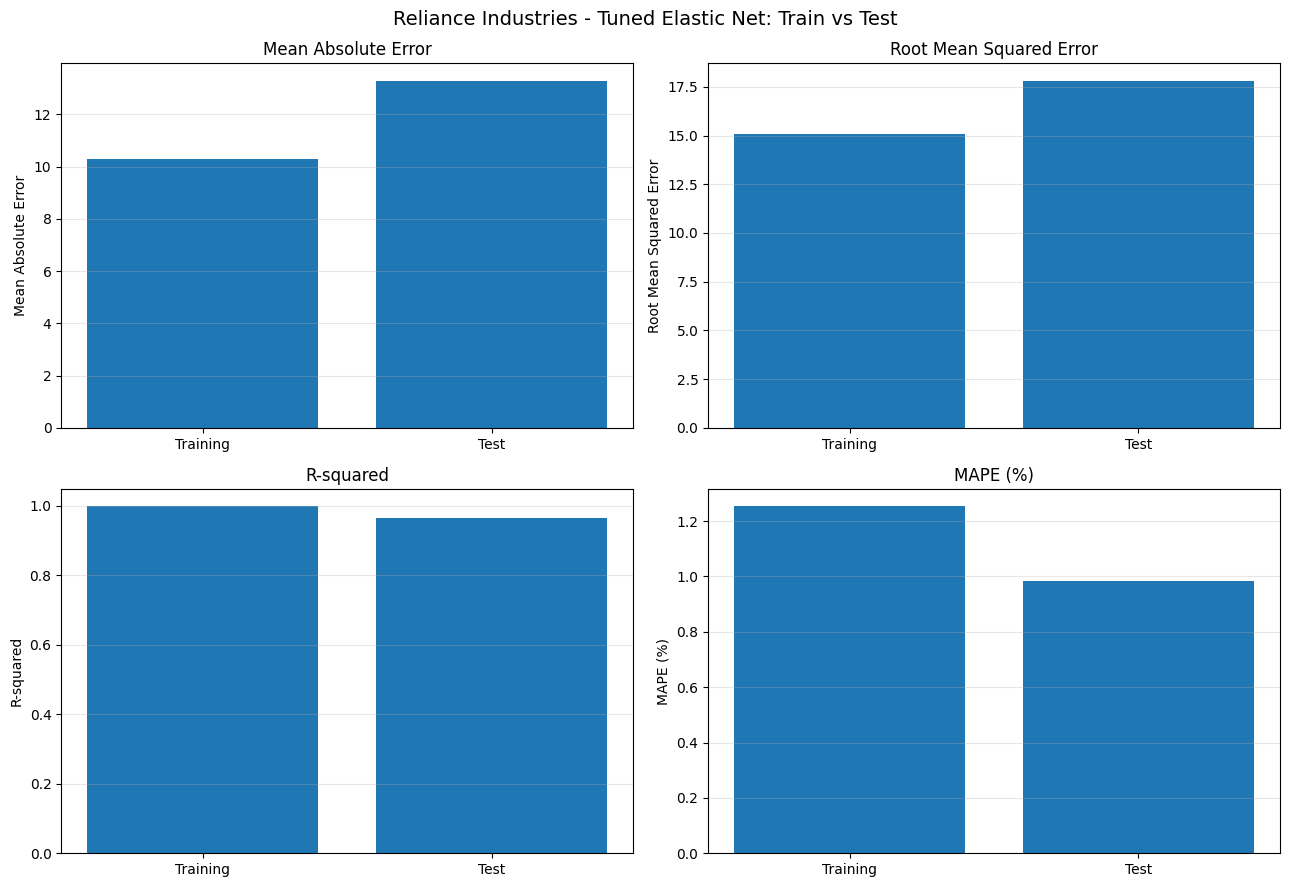

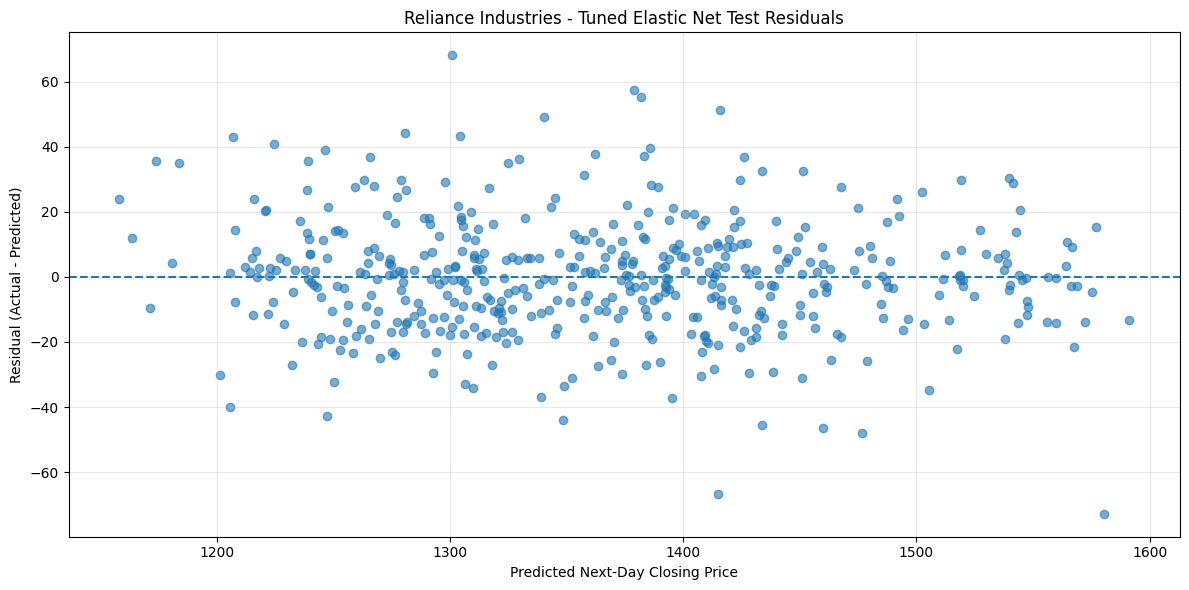


SAVED OUTPUT FILES
---------------------------------------------------------------------------
Train/test metrics: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\overfitting_diagnosis\Reliance_Elastic_Net_Train_Test_Diagnostic_Metrics.csv
Diagnosis summary: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\overfitting_diagnosis\Reliance_Elastic_Net_Overfitting_Underfitting_Diagnosis.csv
Metric comparison graph: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\overfitting_diagnosis\Reliance_Elastic_Net_Train_Test_Metrics.png
Test residual graph: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\elastic_net\hyperparameter_tuning\overfitting_diagnosis\Reliance_Elastic_Net_Test_Residuals.png

STEP 7 COMPLETED SUCCESSFULLY


In [11]:
# =====================================================
# Step 7 — Overfitting and Underfitting Diagnosis
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

diagnosis_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "elastic_net",
    "hyperparameter_tuning",
    "overfitting_diagnosis"
)

os.makedirs(diagnosis_dir, exist_ok=True)

print("=" * 75)
print("RELIANCE INDUSTRIES - ELASTIC NET")
print("STEP 7: OVERFITTING AND UNDERFITTING DIAGNOSIS")
print("=" * 75)

# Generate predictions on training and test datasets
y_train_actual = np.asarray(y_train).reshape(-1)
y_test_actual = np.asarray(y_test).reshape(-1)

y_train_predicted = np.asarray(
    best_elastic_net_model.predict(X_train)
).reshape(-1)

y_test_predicted = np.asarray(
    best_elastic_net_model.predict(X_test)
).reshape(-1)

if len(y_train_actual) != len(y_train_predicted):
    raise ValueError("Training actual and predicted lengths do not match.")

if len(y_test_actual) != len(y_test_predicted):
    raise ValueError("Test actual and predicted lengths do not match.")


def calculate_regression_metrics(actual, predicted):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    nonzero_mask = actual != 0

    if np.any(nonzero_mask):
        mape = np.mean(
            np.abs(
                (
                    actual[nonzero_mask]
                    - predicted[nonzero_mask]
                ) / actual[nonzero_mask]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_Percent": mape
    }


# Evaluate training and test performance
train_metrics = calculate_regression_metrics(
    y_train_actual,
    y_train_predicted
)

test_metrics = calculate_regression_metrics(
    y_test_actual,
    y_test_predicted
)

metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "MAPE_Percent"],
    "Training_Value": [
        train_metrics["MAE"],
        train_metrics["RMSE"],
        train_metrics["R2"],
        train_metrics["MAPE_Percent"]
    ],
    "Test_Value": [
        test_metrics["MAE"],
        test_metrics["RMSE"],
        test_metrics["R2"],
        test_metrics["MAPE_Percent"]
    ]
})

metrics_df["Test_Minus_Train"] = (
    metrics_df["Test_Value"]
    - metrics_df["Training_Value"]
)

print("\nTRAINING VS TEST PERFORMANCE")
print("-" * 75)
display(metrics_df.round(4))

# Calculate Up/Down Directional Accuracy separately
def calculate_directional_accuracy(X, actual, predicted):
    if "Close" not in X.columns:
        return np.nan

    current_close = np.asarray(X["Close"]).reshape(-1)
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)

    actual_direction = np.sign(actual - current_close)
    predicted_direction = np.sign(predicted - current_close)

    return np.mean(
        actual_direction == predicted_direction
    ) * 100


train_directional_accuracy = calculate_directional_accuracy(
    X_train,
    y_train_actual,
    y_train_predicted
)

test_directional_accuracy = calculate_directional_accuracy(
    X_test,
    y_test_actual,
    y_test_predicted
)

print("\nDIRECTIONAL ACCURACY")
print("-" * 55)

if np.isfinite(train_directional_accuracy):
    print(
        "Training Up/Down Directional Accuracy: "
        f"{train_directional_accuracy:.2f}%"
    )
else:
    print("Training directional accuracy unavailable: Close feature missing.")

if np.isfinite(test_directional_accuracy):
    print(
        "Test Up/Down Directional Accuracy: "
        f"{test_directional_accuracy:.2f}%"
    )
else:
    print("Test directional accuracy unavailable: Close feature missing.")

# Calculate generalization gaps
mae_gap = test_metrics["MAE"] - train_metrics["MAE"]
rmse_gap = test_metrics["RMSE"] - train_metrics["RMSE"]
r2_gap = train_metrics["R2"] - test_metrics["R2"]
mape_gap = (
    test_metrics["MAPE_Percent"]
    - train_metrics["MAPE_Percent"]
)

print("\nGENERALIZATION GAP")
print("-" * 55)
print(f"MAE gap (test - train): {mae_gap:.4f}")
print(f"RMSE gap (test - train): {rmse_gap:.4f}")
print(f"R² gap (train - test): {r2_gap:.4f}")
print(f"MAPE gap (test - train): {mape_gap:.4f} percentage points")

# Diagnose model fit using transparent heuristic thresholds
# These thresholds are practical guidelines, not universal statistical rules.
relative_mae_gap = (
    (test_metrics["MAE"] - train_metrics["MAE"])
    / max(abs(train_metrics["MAE"]), 1e-10)
)

relative_rmse_gap = (
    (test_metrics["RMSE"] - train_metrics["RMSE"])
    / max(abs(train_metrics["RMSE"]), 1e-10)
)

train_r2 = train_metrics["R2"]
test_r2 = test_metrics["R2"]

print("\nOVERFITTING / UNDERFITTING DIAGNOSIS")
print("-" * 75)

if (
    relative_mae_gap > 0.20
    or relative_rmse_gap > 0.20
    or r2_gap > 0.10
):
    diagnosis = "Possible Overfitting"

    explanation = (
        "Test performance is noticeably weaker than training performance. "
        "The model may have learned patterns that do not generalize well."
    )

elif (
    train_r2 < 0.50
    and test_r2 < 0.50
    and abs(r2_gap) < 0.10
):
    diagnosis = "Possible Underfitting"

    explanation = (
        "Both training and test R² are relatively low, with a small gap. "
        "The model may not capture the underlying patterns sufficiently."
    )

elif (
    train_r2 >= 0.50
    and test_r2 >= 0.50
    and abs(relative_mae_gap) <= 0.20
    and abs(relative_rmse_gap) <= 0.20
    and abs(r2_gap) <= 0.10
):
    diagnosis = "Reasonable Generalization"

    explanation = (
        "Training and test performance are reasonably close and both R² "
        "values meet the selected heuristic threshold. This suggests "
        "generalization, but does not guarantee future performance."
    )

else:
    diagnosis = "Mixed Results - Further Inspection Needed"

    explanation = (
        "The metrics do not clearly indicate overfitting or underfitting. "
        "Inspect the metric gaps, residuals, and performance on later "
        "time periods before drawing a conclusion."
    )

print("Diagnosis:", diagnosis)
print(explanation)

print("\nTHRESHOLDS USED")
print("-" * 55)
print("Relative MAE/RMSE gap above 20%: possible overfitting.")
print("Train-test R² gap above 0.10: possible overfitting.")
print("Both R² values below 0.50 with a small gap: possible underfitting.")
print("These are diagnostic heuristics, not universal cutoffs.")

# Save training-versus-test metrics
metrics_path = os.path.join(
    diagnosis_dir,
    "Reliance_Elastic_Net_Train_Test_Diagnostic_Metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

# Save diagnostic summary
diagnosis_df = pd.DataFrame({
    "Item": [
        "Diagnosis",
        "Explanation",
        "Relative_MAE_Gap",
        "Relative_RMSE_Gap",
        "Train_R2",
        "Test_R2",
        "Train_Directional_Accuracy_Percent",
        "Test_Directional_Accuracy_Percent"
    ],
    "Value": [
        diagnosis,
        explanation,
        relative_mae_gap,
        relative_rmse_gap,
        train_r2,
        test_r2,
        train_directional_accuracy,
        test_directional_accuracy
    ]
})

diagnosis_path = os.path.join(
    diagnosis_dir,
    "Reliance_Elastic_Net_Overfitting_Underfitting_Diagnosis.csv"
)

diagnosis_df.to_csv(diagnosis_path, index=False)

# Plot training versus test metrics
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metric_plot_settings = [
    ("MAE", "Mean Absolute Error"),
    ("RMSE", "Root Mean Squared Error"),
    ("R2", "R-squared"),
    ("MAPE_Percent", "MAPE (%)")
]

for ax, (metric, title) in zip(
    axes.flatten(),
    metric_plot_settings
):
    values = [
        train_metrics[metric],
        test_metrics[metric]
    ]

    ax.bar(
        ["Training", "Test"],
        values
    )

    ax.set_title(title)
    ax.set_ylabel(title)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Reliance Industries - Tuned Elastic Net: Train vs Test",
    fontsize=14
)

plt.tight_layout()

comparison_plot_path = os.path.join(
    diagnosis_dir,
    "Reliance_Elastic_Net_Train_Test_Metrics.png"
)

plt.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot test residuals
test_residuals = y_test_actual - y_test_predicted

plt.figure(figsize=(12, 6))

plt.scatter(
    y_test_predicted,
    test_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Predicted Next-Day Closing Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title(
    "Reliance Industries - Tuned Elastic Net Test Residuals"
)

plt.grid(alpha=0.3)
plt.tight_layout()

residual_plot_path = os.path.join(
    diagnosis_dir,
    "Reliance_Elastic_Net_Test_Residuals.png"
)

plt.savefig(
    residual_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSAVED OUTPUT FILES")
print("-" * 75)
print("Train/test metrics:", metrics_path)
print("Diagnosis summary:", diagnosis_path)
print("Metric comparison graph:", comparison_plot_path)
print("Test residual graph:", residual_plot_path)

print("\nSTEP 7 COMPLETED SUCCESSFULLY")
print("=" * 75)


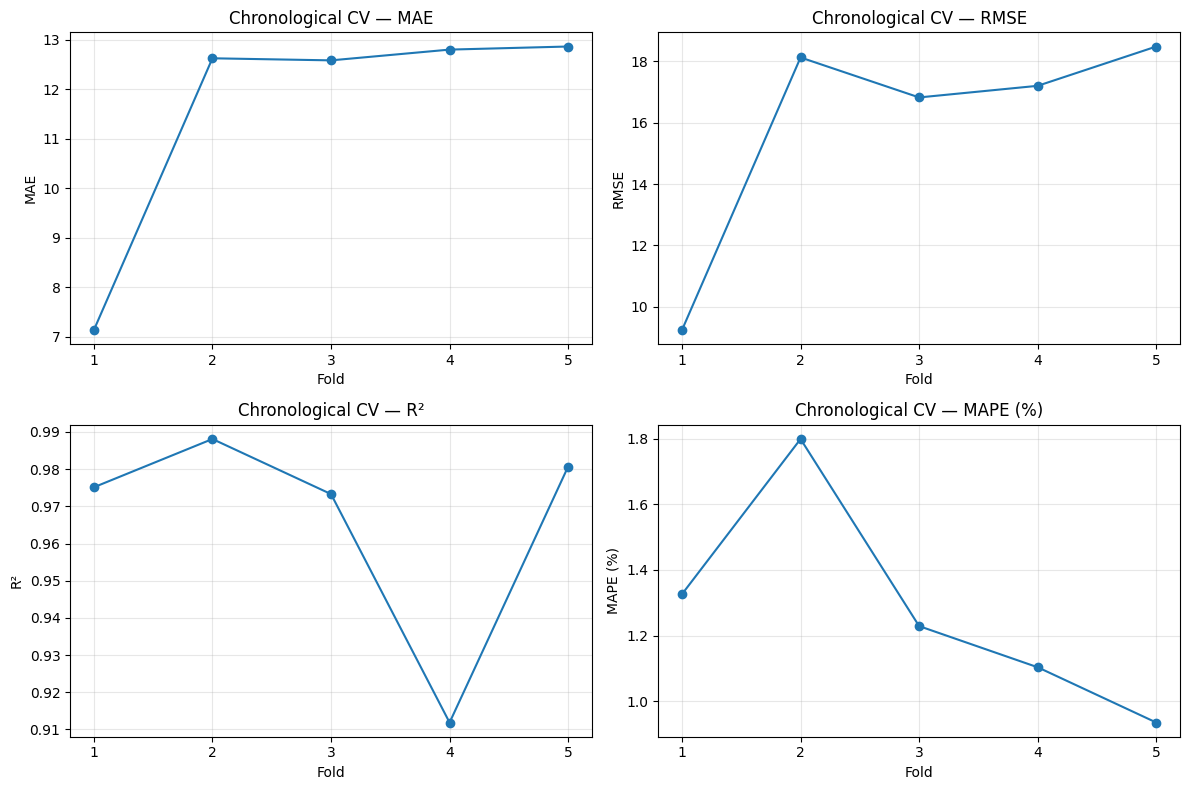

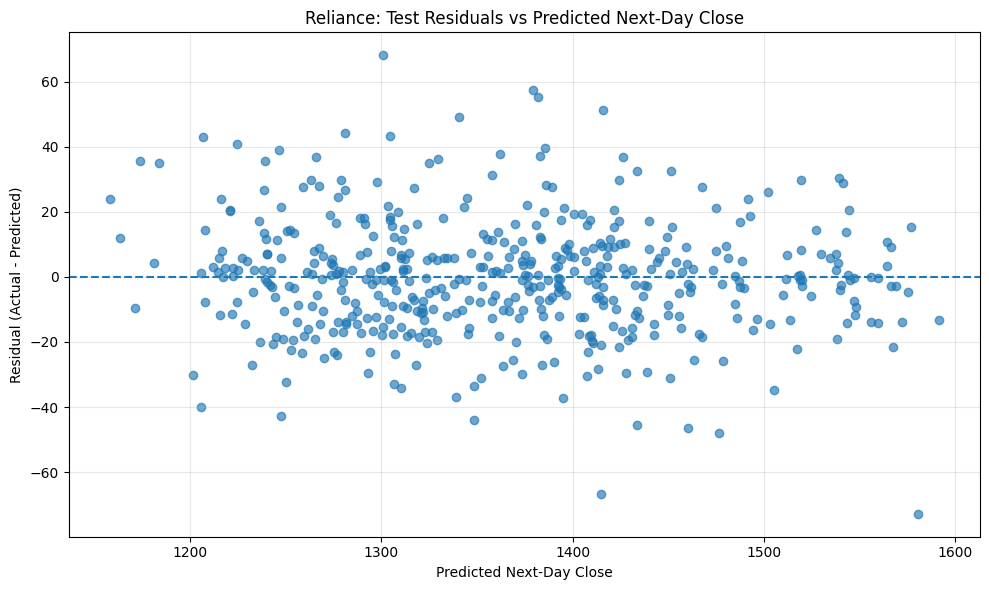

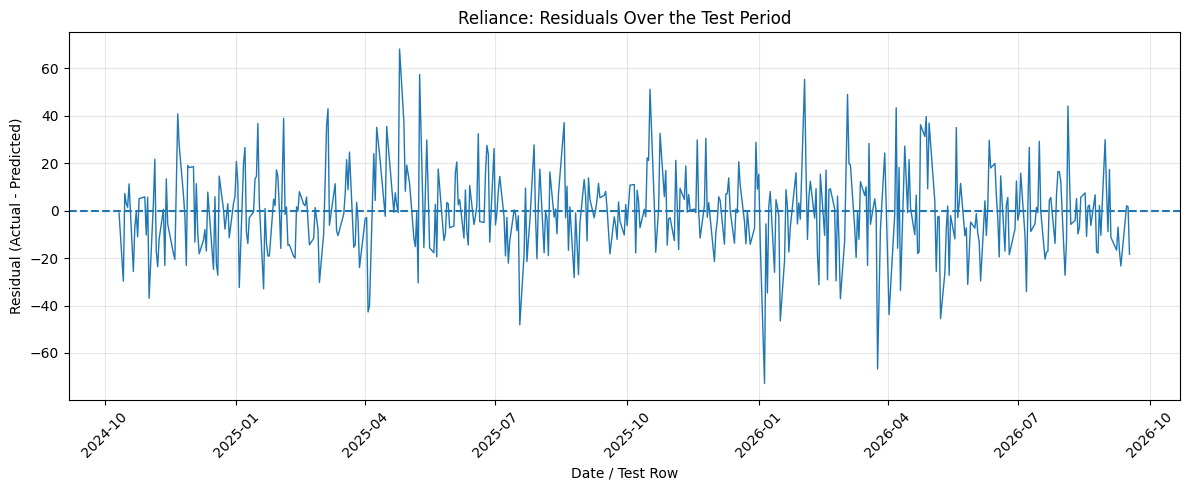

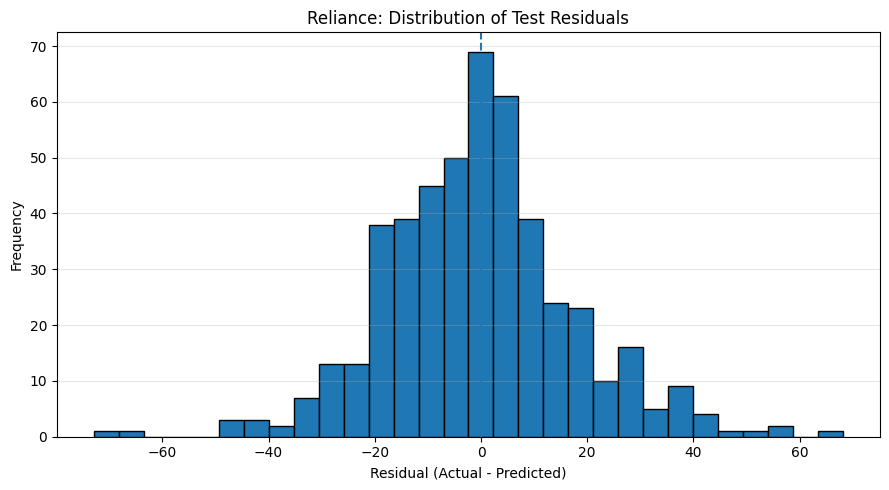


STEP 8 — RESULTS

CHRONOLOGICAL CROSS-VALIDATION RESULTS
 Fold  Training_Rows  Validation_Rows     MAE    RMSE     R2  MAPE_Percent
    1            324              319  7.1307  9.2368 0.9751        1.3263
    2            643              319 12.6223 18.1294 0.9881        1.7988
    3            962              319 12.5803 16.8256 0.9733        1.2291
    4           1281              319 12.7979 17.2047 0.9118        1.1038
    5           1600              319 12.8603 18.4870 0.9807        0.9354

CROSS-VALIDATION SUMMARY
                 Mean  Standard_Deviation
MAE           11.5983              2.5002
RMSE          15.9767              3.8272
R2             0.9658              0.0307
MAPE_Percent   1.2787              0.3255

HELD-OUT TEST SET RESULTS
Test MAE:  13.2948
Test RMSE: 17.8140
Test R²:   0.9653
Test MAPE: 0.9819%

RESIDUAL STATISTICS
Residual Mean: -0.3883
Residual Standard Deviation: 17.8283
Residual Median: -0.5469
Lag-1 Residual Autocorrelation: 0.1113

STEP 8 —

In [13]:
# Step 8 — Chronological Cross-Validation and Residual Analysis

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

required_variables = [
    "project_path", "X_train", "y_train",
    "X_test", "y_test", "best_elastic_net_model"
]

missing_variables = [v for v in required_variables if v not in globals()]
if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run the previous model-training cells first."
    )

output_dir = os.path.join(
    project_path,
    "data", "processed", "stock",
    "elastic_net", "hyperparameter_tuning",
    "chronological_validation"
)
os.makedirs(output_dir, exist_ok=True)

X_train_cv = X_train.reset_index(drop=True)
y_train_cv = pd.Series(y_train).reset_index(drop=True)
X_test_eval = X_test.reset_index(drop=True)
y_test_eval = pd.Series(y_test).reset_index(drop=True)

if len(X_train_cv) < 6:
    raise ValueError("Insufficient training rows for chronological cross-validation.")

if len(X_train_cv) != len(y_train_cv):
    raise ValueError("X_train and y_train have different lengths.")

if len(X_test_eval) != len(y_test_eval):
    raise ValueError("X_test and y_test have different lengths.")

# Chronological cross-validation using training data only
tscv = TimeSeriesSplit(n_splits=5)
cv_records = []

for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(X_train_cv), start=1
):
    fold_model = clone(best_elastic_net_model)

    X_fold_train = X_train_cv.iloc[train_idx]
    y_fold_train = y_train_cv.iloc[train_idx]
    X_fold_valid = X_train_cv.iloc[valid_idx]
    y_fold_valid = y_train_cv.iloc[valid_idx]

    fold_model.fit(X_fold_train, y_fold_train)

    actual = np.asarray(y_fold_valid).ravel()
    predicted = np.asarray(fold_model.predict(X_fold_valid)).ravel()

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    nonzero = actual != 0
    mape = (
        np.mean(np.abs((actual[nonzero] - predicted[nonzero]) /
                       actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    cv_records.append({
        "Fold": fold,
        "Training_Rows": len(train_idx),
        "Validation_Rows": len(valid_idx),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_Percent": mape
    })

cv_df = pd.DataFrame(cv_records)

cv_results_path = os.path.join(
    output_dir, "Reliance_Chronological_CV_Results.csv"
)
cv_df.to_csv(cv_results_path, index=False)

cv_summary_df = cv_df[
    ["MAE", "RMSE", "R2", "MAPE_Percent"]
].agg(["mean", "std"]).T
cv_summary_df.columns = ["Mean", "Standard_Deviation"]

cv_summary_path = os.path.join(
    output_dir, "Reliance_Chronological_CV_Summary.csv"
)
cv_summary_df.to_csv(cv_summary_path)

# Plot cross-validation metrics
cv_plot_path = os.path.join(
    output_dir, "Reliance_CV_Metrics_By_Fold.png"
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

metrics = [
    ("MAE", "MAE"),
    ("RMSE", "RMSE"),
    ("R2", "R²"),
    ("MAPE_Percent", "MAPE (%)")
]

for ax, (column, title) in zip(axes.ravel(), metrics):
    ax.plot(cv_df["Fold"], cv_df[column], marker="o")
    ax.set_title(f"Chronological CV — {title}")
    ax.set_xlabel("Fold")
    ax.set_ylabel(title)
    ax.set_xticks(cv_df["Fold"])
    ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(cv_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Evaluate the tuned model on the held-out test set
test_actual = np.asarray(y_test_eval).ravel()
test_predictions = np.asarray(
    best_elastic_net_model.predict(X_test_eval)
).ravel()

residuals = test_actual - test_predictions

test_mae = mean_absolute_error(test_actual, test_predictions)
test_rmse = np.sqrt(mean_squared_error(test_actual, test_predictions))
test_r2 = r2_score(test_actual, test_predictions)

nonzero_test = test_actual != 0
test_mape = (
    np.mean(np.abs(
        (test_actual[nonzero_test] - test_predictions[nonzero_test])
        / test_actual[nonzero_test]
    )) * 100
    if nonzero_test.any() else np.nan
)

residual_mean = float(np.mean(residuals))
residual_std = (
    float(np.std(residuals, ddof=1))
    if len(residuals) > 1 else 0.0
)
residual_median = float(np.median(residuals))

if (
    len(residuals) > 1
    and np.std(residuals[:-1]) > 0
    and np.std(residuals[1:]) > 0
):
    lag1_autocorrelation = float(
        np.corrcoef(residuals[:-1], residuals[1:])[0, 1]
    )
else:
    lag1_autocorrelation = np.nan

# Use dates if the original dataframe and split index are available
if "df" in globals() and "Date" in getattr(df, "columns", []):
    if "split_index" in globals():
        test_dates = pd.to_datetime(
            df["Date"].iloc[split_index:]
        ).reset_index(drop=True)
    else:
        test_dates = pd.Series(
            np.arange(len(test_actual)), name="Test_Row"
        )
else:
    test_dates = pd.Series(
        np.arange(len(test_actual)), name="Test_Row"
    )

if len(test_dates) != len(test_actual):
    test_dates = pd.Series(
        np.arange(len(test_actual)), name="Test_Row"
    )

residuals_df = pd.DataFrame({
    "Date_or_Test_Row": test_dates,
    "Actual_Next_Day_Close": test_actual,
    "Predicted_Next_Day_Close": test_predictions,
    "Residual_Actual_Minus_Predicted": residuals,
    "Absolute_Error": np.abs(residuals)
})

residuals_path = os.path.join(
    output_dir, "Reliance_Test_Set_Residuals.csv"
)
residuals_df.to_csv(residuals_path, index=False)

residual_summary_df = pd.DataFrame({
    "Metric": [
        "Test MAE", "Test RMSE", "Test R2", "Test MAPE (%)",
        "Residual Mean", "Residual Standard Deviation",
        "Residual Median", "Lag-1 Residual Autocorrelation"
    ],
    "Value": [
        test_mae, test_rmse, test_r2, test_mape,
        residual_mean, residual_std, residual_median,
        lag1_autocorrelation
    ]
})

residual_summary_path = os.path.join(
    output_dir, "Reliance_Residual_Analysis_Summary.csv"
)
residual_summary_df.to_csv(residual_summary_path, index=False)

# Residuals versus predicted values
residual_scatter_path = os.path.join(
    output_dir, "Reliance_Residuals_vs_Predicted.png"
)

plt.figure(figsize=(10, 6))
plt.scatter(test_predictions, residuals, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.title("Reliance: Test Residuals vs Predicted Next-Day Close")
plt.xlabel("Predicted Next-Day Close")
plt.ylabel("Residual (Actual - Predicted)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(residual_scatter_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Residuals over the test period
residual_time_path = os.path.join(
    output_dir, "Reliance_Residuals_Over_Test_Period.png"
)

plt.figure(figsize=(12, 5))
plt.plot(test_dates, residuals, linewidth=1)
plt.axhline(0, linestyle="--")
plt.title("Reliance: Residuals Over the Test Period")
plt.xlabel("Date / Test Row")
plt.ylabel("Residual (Actual - Predicted)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(residual_time_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Residual distribution
residual_hist_path = os.path.join(
    output_dir, "Reliance_Residual_Distribution.png"
)

plt.figure(figsize=(9, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.title("Reliance: Distribution of Test Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(residual_hist_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# RESULTS
print("\n" + "=" * 75)
print("STEP 8 — RESULTS")
print("=" * 75)

print("\nCHRONOLOGICAL CROSS-VALIDATION RESULTS")
print(cv_df.round(4).to_string(index=False))

print("\nCROSS-VALIDATION SUMMARY")
print(cv_summary_df.round(4).to_string())

print("\nHELD-OUT TEST SET RESULTS")
print(f"Test MAE:  {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R²:   {test_r2:.4f}")
print(
    f"Test MAPE: {test_mape:.4f}%"
    if np.isfinite(test_mape)
    else "Test MAPE: unavailable"
)

print("\nRESIDUAL STATISTICS")
print(f"Residual Mean: {residual_mean:.4f}")
print(f"Residual Standard Deviation: {residual_std:.4f}")
print(f"Residual Median: {residual_median:.4f}")
print(
    f"Lag-1 Residual Autocorrelation: {lag1_autocorrelation:.4f}"
    if np.isfinite(lag1_autocorrelation)
    else "Lag-1 Residual Autocorrelation: unavailable"
)

# INTERPRETATION
print("\n" + "=" * 75)
print("STEP 8 — INTERPRETATION")
print("=" * 75)

cv_mae_mean = cv_df["MAE"].mean()
cv_mae_std = cv_df["MAE"].std(ddof=1)

if (
    np.isfinite(cv_mae_mean)
    and abs(cv_mae_mean) > 0
    and np.isfinite(cv_mae_std)
):
    cv_mae_variability = cv_mae_std / abs(cv_mae_mean) * 100
    print(f"CV MAE variability: {cv_mae_variability:.2f}% of mean CV MAE.")

    if cv_mae_variability <= 15:
        print("Interpretation: Validation MAE was relatively consistent across folds.")
    else:
        print(
            "Interpretation: Validation MAE varied across folds; "
            "performance may depend on the market period."
        )
else:
    print("CV MAE variability could not be calculated.")

if test_mae > 0 and abs(residual_mean) < 0.1 * test_mae:
    print("Mean residual is small relative to MAE, suggesting limited average bias.")
elif residual_mean > 0:
    print("Positive mean residual indicates average underprediction.")
elif residual_mean < 0:
    print("Negative mean residual indicates average overprediction.")
else:
    print("Average residual is zero.")

if (
    np.isfinite(lag1_autocorrelation)
    and abs(lag1_autocorrelation) >= 0.3
):
    print(
        "Lag-1 residual correlation is notable; inspect time patterns "
        "the model may not capture."
    )
elif np.isfinite(lag1_autocorrelation):
    print(
        "Lag-1 residual correlation is not large under the 0.3 heuristic; "
        "other residual patterns may still exist."
    )
else:
    print("Residual autocorrelation could not be assessed reliably.")

print(
    "Check residual plots for patterns, changing spread, outliers, "
    "and systematic prediction errors."
)

# CONCLUSION
print("\n" + "=" * 75)
print("STEP 8 — CONCLUSION")
print("=" * 75)

print(
    "Chronological cross-validation assesses model stability across "
    "sequential validation periods within the training data."
)
print(
    "Residual analysis examines held-out test errors for bias, spread, "
    "distribution, and serial correlation."
)
print(
    "Consider the cross-validation metrics, test metrics, and residual "
    "plots together when judging generalization. These checks do not "
    "prove that overfitting is absent or guarantee future stock-price accuracy."
)

# SAVED FILES
print("\n" + "=" * 75)
print("STEP 8 — SAVED OUTPUT FILES")
print("=" * 75)

for saved_path in [
    cv_results_path,
    cv_summary_path,
    cv_plot_path,
    residuals_path,
    residual_summary_path,
    residual_scatter_path,
    residual_time_path,
    residual_hist_path
]:
    print(saved_path)

print("\nSTEP 8 COMPLETED SUCCESSFULLY")


STEP 9 — WORKFLOW OVERLAP AUDIT

ACTIVITY-BY-ACTIVITY COMPARISON
                           Activity                Step_8                                 Step_9                 Overlap
     Chronological cross-validation                   Yes No, reuse existing Elastic Net results No redundant repetition
                  Residual analysis                   Yes                                     No                      No
             MAE, RMSE, R2 and MAPE                   Yes                                    Yes  Necessary metric reuse
Evaluate multiple regression models                    No                                    Yes                      No
          Compare model performance       One tuned model                        Multiple models     Different objective
          Residual diagnostic plots                   Yes                                     No                      No
             Model comparison plots                    No                               

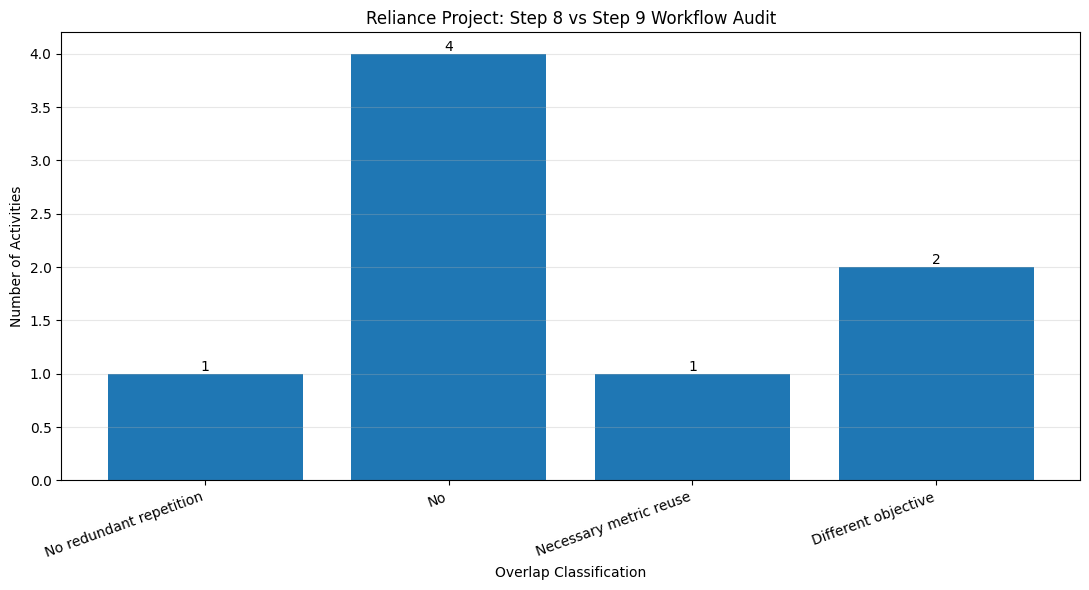

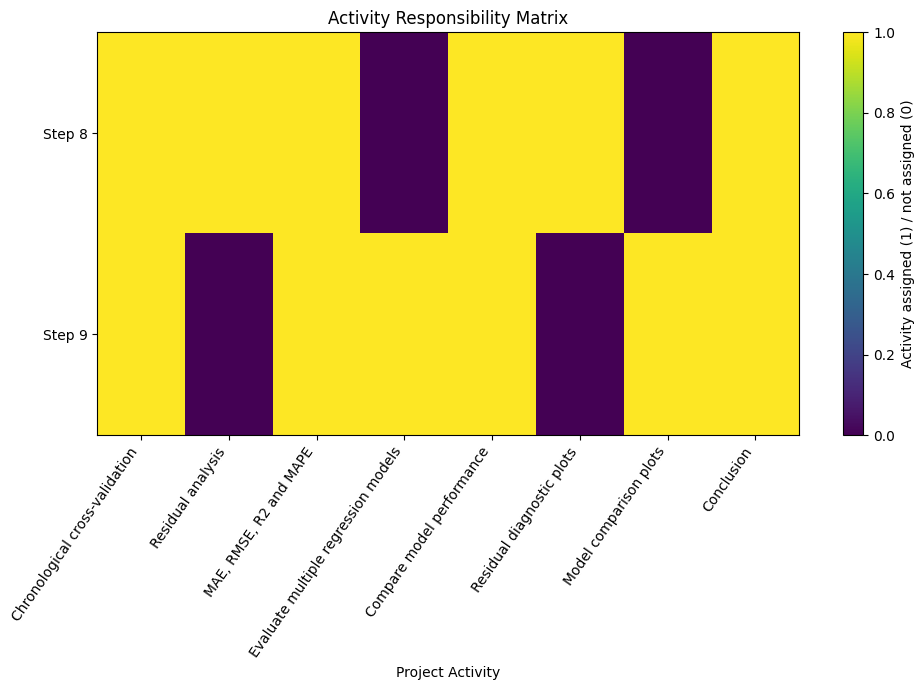


RESULTS
Activities audited: 8
Activities involving necessary metric reuse: 1
Activities with explicitly different objectives: 2
Activities assigned to different stages or not repeated: 5

INTERPRETATION
Step 8 focuses on validating the tuned Elastic Net model using chronological cross-validation and residual analysis.
Step 9 focuses on comparing multiple regression algorithms using consistent evaluation metrics.
The evaluation metrics appear in both stages because they serve different purposes. Their reuse is necessary and does not by itself represent redundant analysis.
The audit is based on the declared workflow. It does not automatically inspect notebook source code to prove that no operations have been duplicated.

CONCLUSION
Based on the defined workflow, Step 8 and Step 9 have distinct primary objectives and no planned redundant cross-validation or residual analysis.
Reuse the existing tuned Elastic Net results in Step 9, then evaluate competing models on the same chronological 

In [14]:
# Step 9 — Workflow Overlap and Redundancy Verification

import os
import pandas as pd
import matplotlib.pyplot as plt

project_path = globals().get(
    "project_path",
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

output_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "elastic_net",
    "hyperparameter_tuning",
    "workflow_overlap_audit"
)
os.makedirs(output_dir, exist_ok=True)

# Define the responsibilities of each step
audit_records = [
    {
        "Activity": "Chronological cross-validation",
        "Step_8": "Yes",
        "Step_9": "No, reuse existing Elastic Net results",
        "Overlap": "No redundant repetition",
        "Explanation": (
            "Step 8 validates the tuned Elastic Net model. "
            "Step 9 can reuse its existing validation results."
        )
    },
    {
        "Activity": "Residual analysis",
        "Step_8": "Yes",
        "Step_9": "No",
        "Overlap": "No",
        "Explanation": (
            "Residual diagnostics belong to Step 8. "
            "They need not be repeated during model comparison."
        )
    },
    {
        "Activity": "MAE, RMSE, R2 and MAPE",
        "Step_8": "Yes",
        "Step_9": "Yes",
        "Overlap": "Necessary metric reuse",
        "Explanation": (
            "The same metrics are needed to compare models fairly. "
            "Reusing metric names is not duplicated analysis."
        )
    },
    {
        "Activity": "Evaluate multiple regression models",
        "Step_8": "No",
        "Step_9": "Yes",
        "Overlap": "No",
        "Explanation": (
            "Step 9 compares different regression algorithms "
            "on the same chronological test period."
        )
    },
    {
        "Activity": "Compare model performance",
        "Step_8": "One tuned model",
        "Step_9": "Multiple models",
        "Overlap": "Different objective",
        "Explanation": (
            "Step 8 assesses one model's reliability. "
            "Step 9 ranks model performance."
        )
    },
    {
        "Activity": "Residual diagnostic plots",
        "Step_8": "Yes",
        "Step_9": "No",
        "Overlap": "No",
        "Explanation": (
            "Step 8 plots residual behaviour. Step 9 plots "
            "comparative performance metrics."
        )
    },
    {
        "Activity": "Model comparison plots",
        "Step_8": "No",
        "Step_9": "Yes",
        "Overlap": "No",
        "Explanation": (
            "Step 9 produces comparative metric charts "
            "that are different from Step 8's residual plots."
        )
    },
    {
        "Activity": "Conclusion",
        "Step_8": "Validation conclusion",
        "Step_9": "Model selection conclusion",
        "Overlap": "Different objective",
        "Explanation": (
            "Step 8 concludes on validation and residuals. "
            "Step 9 recommends a model based on comparative evidence."
        )
    }
]

audit_df = pd.DataFrame(audit_records)

# Count the types of overlap
overlap_counts = audit_df["Overlap"].value_counts()

# Save audit results
audit_csv_path = os.path.join(
    output_dir,
    "Reliance_Step8_Step9_Overlap_Audit.csv"
)
audit_df.to_csv(audit_csv_path, index=False)

summary_df = pd.DataFrame({
    "Overlap_Category": overlap_counts.index,
    "Number_of_Activities": overlap_counts.values
})

summary_csv_path = os.path.join(
    output_dir,
    "Reliance_Overlap_Audit_Summary.csv"
)
summary_df.to_csv(summary_csv_path, index=False)

# Print the audit table
print("=" * 80)
print("STEP 9 — WORKFLOW OVERLAP AUDIT")
print("=" * 80)

print("\nACTIVITY-BY-ACTIVITY COMPARISON")
print(
    audit_df[
        ["Activity", "Step_8", "Step_9", "Overlap"]
    ].to_string(index=False)
)

print("\nOVERLAP CATEGORY SUMMARY")
print(summary_df.to_string(index=False))

# Plot the overlap classification
plot_df = audit_df.copy()

category_order = [
    "No redundant repetition",
    "No",
    "Necessary metric reuse",
    "Different objective"
]

category_counts = (
    plot_df["Overlap"]
    .value_counts()
    .reindex(category_order, fill_value=0)
)

plot_path = os.path.join(
    output_dir,
    "Reliance_Step8_Step9_Overlap_Analysis.png"
)

plt.figure(figsize=(11, 6))
bars = plt.bar(
    category_counts.index,
    category_counts.values
)

plt.title("Reliance Project: Step 8 vs Step 9 Workflow Audit")
plt.xlabel("Overlap Classification")
plt.ylabel("Number of Activities")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Plot the activity responsibility matrix
step8_values = [1 if x in ["Yes", "One tuned model",
                            "Validation conclusion"] else 0
                for x in audit_df["Step_8"]]

step9_values = [0 if x == "No" else 1
                for x in audit_df["Step_9"]]

matrix_path = os.path.join(
    output_dir,
    "Reliance_Step8_Step9_Activity_Matrix.png"
)

plt.figure(figsize=(10, 7))
plt.imshow(
    [step8_values, step9_values],
    aspect="auto",
    interpolation="nearest"
)
plt.yticks([0, 1], ["Step 8", "Step 9"])
plt.xticks(
    range(len(audit_df)),
    audit_df["Activity"],
    rotation=55,
    ha="right"
)
plt.title("Activity Responsibility Matrix")
plt.xlabel("Project Activity")
plt.colorbar(
    label="Activity assigned (1) / not assigned (0)"
)
plt.tight_layout()
plt.savefig(matrix_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# RESULTS
print("\n" + "=" * 80)
print("RESULTS")
print("=" * 80)

print(f"Activities audited: {len(audit_df)}")
print(
    "Activities involving necessary metric reuse:",
    int((audit_df["Overlap"] == "Necessary metric reuse").sum())
)
print(
    "Activities with explicitly different objectives:",
    int((audit_df["Overlap"] == "Different objective").sum())
)
print(
    "Activities assigned to different stages or not repeated:",
    int(audit_df["Overlap"].isin(
        ["No", "No redundant repetition"]
    ).sum())
)

# INTERPRETATION
print("\n" + "=" * 80)
print("INTERPRETATION")
print("=" * 80)

print(
    "Step 8 focuses on validating the tuned Elastic Net model "
    "using chronological cross-validation and residual analysis."
)
print(
    "Step 9 focuses on comparing multiple regression algorithms "
    "using consistent evaluation metrics."
)
print(
    "The evaluation metrics appear in both stages because they "
    "serve different purposes. Their reuse is necessary and "
    "does not by itself represent redundant analysis."
)
print(
    "The audit is based on the declared workflow. It does not "
    "automatically inspect notebook source code to prove that "
    "no operations have been duplicated."
)

# CONCLUSION
print("\n" + "=" * 80)
print("CONCLUSION")
print("=" * 80)

print(
    "Based on the defined workflow, Step 8 and Step 9 have "
    "distinct primary objectives and no planned redundant "
    "cross-validation or residual analysis."
)
print(
    "Reuse the existing tuned Elastic Net results in Step 9, "
    "then evaluate competing models on the same chronological "
    "test period. If cross-validation is used for all models, "
    "reuse the existing Elastic Net fold results where compatible."
)
print(
    "Therefore, the planned workflow has no major conceptual "
    "overlap, although it shares evaluation metrics."
)

# OUTPUT FILES
print("\n" + "=" * 80)
print("SAVED OUTPUT FILES")
print("=" * 80)

for path in [
    audit_csv_path,
    summary_csv_path,
    plot_path,
    matrix_path
]:
    print(path)

print("\nWORKFLOW OVERLAP AUDIT COMPLETED")


RELIANCE STOCK PRICE PREDICTION — FINAL EVALUATION

EVALUATION METRICS
          Evaluation Type     MAE    RMSE     R²  MAPE (%)  Custom Score (%)
Original Elastic Net Test 15.4166 20.3840 0.9546    1.1334           98.8666
   Tuned Elastic Net Test 13.2948 17.8140 0.9653    0.9819           99.0181
    Chronological CV Mean 11.5983 15.9767 0.9658    1.2787           98.7213


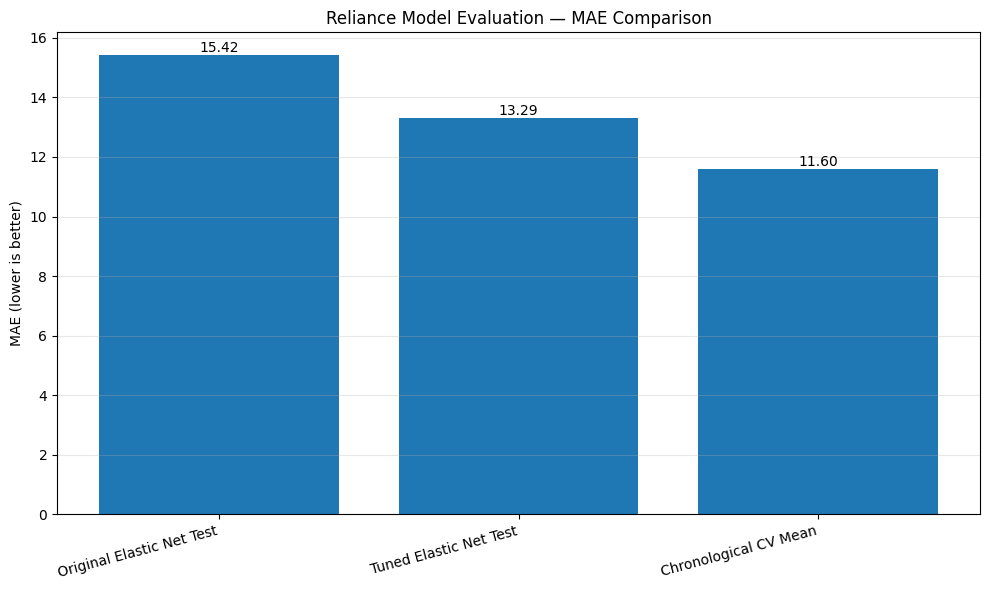

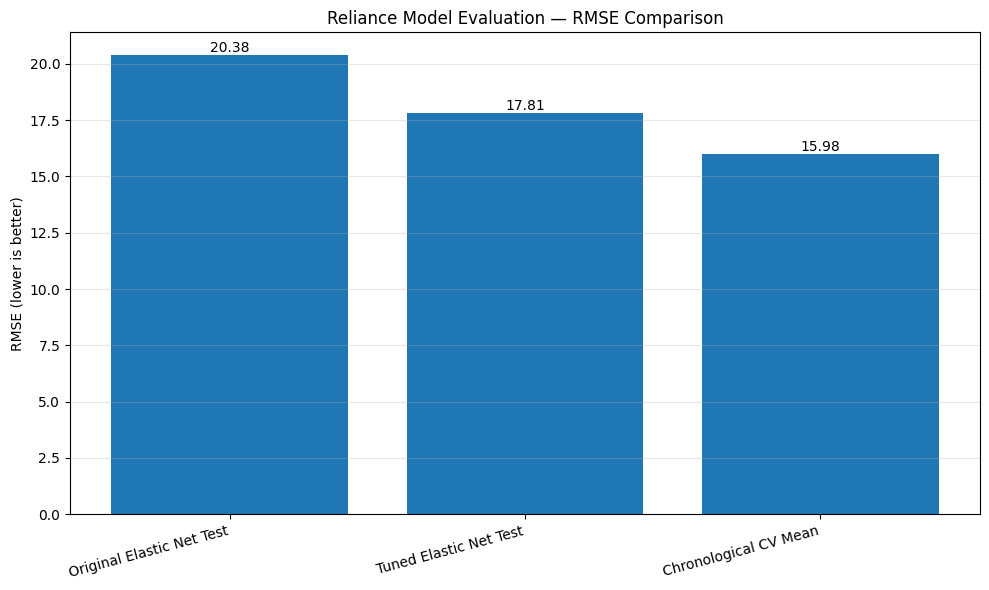

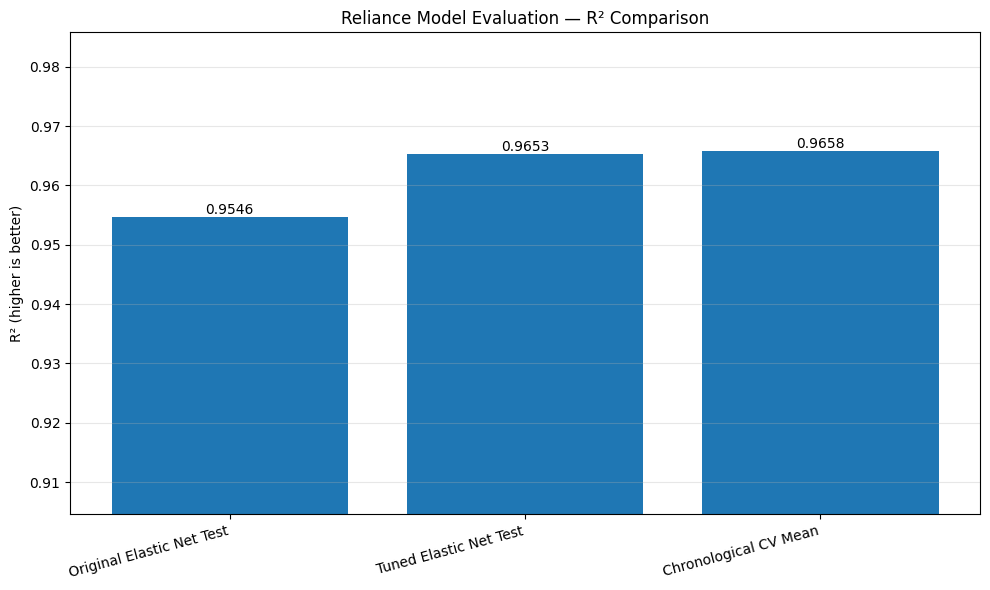

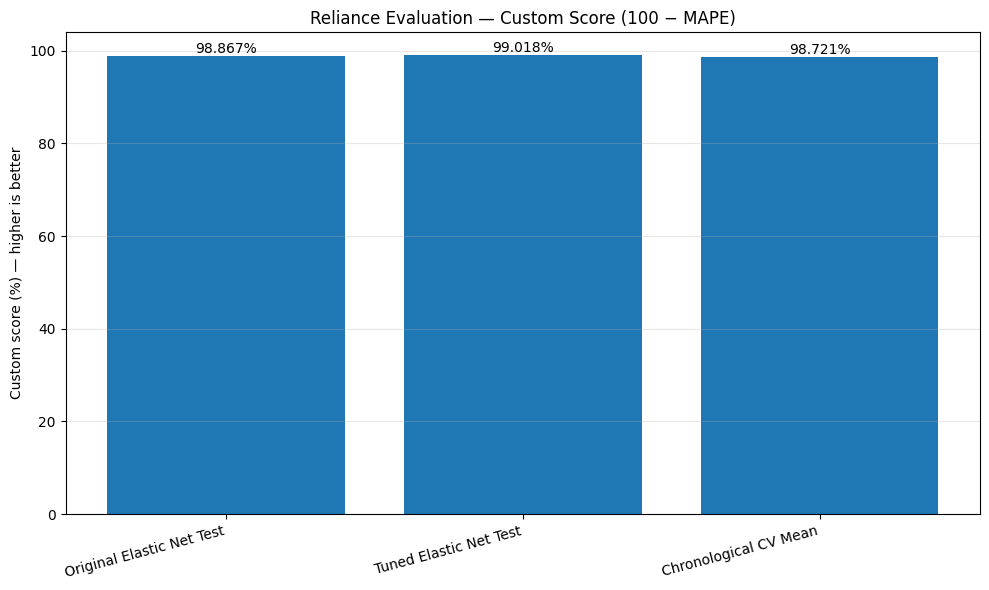


INTERPRETATION
1. MAE decreased by 13.76% after tuning, indicating smaller average absolute prediction errors.
2. RMSE decreased by 12.61%, indicating improvement under a metric that penalizes larger errors.
3. R² increased from 0.9546 to 0.9653, a change of 0.0107.
4. MAPE decreased by 0.1515 percentage points after tuning.
5. Chronological CV mean MAE is 11.5983, with mean R² of 0.9658. CV results summarize validation folds and are not another test model.
6. Custom score is calculated as 100 minus MAPE. It is not standard classification accuracy.

FINAL CONCLUSION
The tuned Elastic Net model performs better than the original Elastic Net model on the reported held-out test metrics: MAE, RMSE, R², and MAPE.
The tuned model's test MAE is 13.2948, RMSE is 17.8140, R² is 0.9653, and MAPE is 0.9819%.
Chronological cross-validation provides additional evidence about performance across different training periods. The final model should still be compared with other regression algorithms befo

In [15]:
# Final Evaluation — Reliance Stock Price Prediction

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Output directory
project_path = globals().get(
    "project_path",
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

output_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "final_model_evaluation"
)
os.makedirs(output_dir, exist_ok=True)

# Previously obtained evaluation results
results = [
    {
        "Evaluation": "Original Elastic Net Test",
        "MAE": 15.4166,
        "RMSE": 20.3840,
        "R2": 0.9546,
        "MAPE_Percent": 1.1334
    },
    {
        "Evaluation": "Tuned Elastic Net Test",
        "MAE": 13.2948,
        "RMSE": 17.8140,
        "R2": 0.9653,
        "MAPE_Percent": 0.9819
    },
    {
        "Evaluation": "Chronological CV Mean",
        "MAE": 11.5983,
        "RMSE": 15.9767,
        "R2": 0.9658,
        "MAPE_Percent": 1.2787
    }
]

metrics_df = pd.DataFrame(results)

# Custom indicator, not standard classification accuracy
metrics_df["Custom_Score_Percent"] = (
    100 - metrics_df["MAPE_Percent"]
)

# Save metrics
csv_path = os.path.join(
    output_dir,
    "Reliance_Final_Evaluation_Metrics.csv"
)
metrics_df.to_csv(csv_path, index=False)

# Display results table
print("=" * 80)
print("RELIANCE STOCK PRICE PREDICTION — FINAL EVALUATION")
print("=" * 80)

display_df = metrics_df.copy()
display_df = display_df.rename(columns={
    "Evaluation": "Evaluation Type",
    "R2": "R²",
    "MAPE_Percent": "MAPE (%)",
    "Custom_Score_Percent": "Custom Score (%)"
})

print("\nEVALUATION METRICS")
print(display_df.round(4).to_string(index=False))

# Graph 1 — MAE comparison
mae_path = os.path.join(output_dir, "MAE_Comparison.png")

plt.figure(figsize=(10, 6))
bars = plt.bar(metrics_df["Evaluation"], metrics_df["MAE"])
plt.title("Reliance Model Evaluation — MAE Comparison")
plt.ylabel("MAE (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(mae_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Graph 2 — RMSE comparison
rmse_path = os.path.join(output_dir, "RMSE_Comparison.png")

plt.figure(figsize=(10, 6))
bars = plt.bar(metrics_df["Evaluation"], metrics_df["RMSE"])
plt.title("Reliance Model Evaluation — RMSE Comparison")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(rmse_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Graph 3 — R-squared comparison
r2_path = os.path.join(output_dir, "R2_Comparison.png")

plt.figure(figsize=(10, 6))
bars = plt.bar(metrics_df["Evaluation"], metrics_df["R2"])
plt.title("Reliance Model Evaluation — R² Comparison")
plt.ylabel("R² (higher is better)")
plt.ylim(
    max(0, metrics_df["R2"].min() - 0.05),
    min(1.05, metrics_df["R2"].max() + 0.02)
)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(r2_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Graph 4 — Custom score comparison
score_path = os.path.join(
    output_dir, "Custom_Score_Comparison.png"
)

plt.figure(figsize=(10, 6))
bars = plt.bar(
    metrics_df["Evaluation"],
    metrics_df["Custom_Score_Percent"]
)
plt.title("Reliance Evaluation — Custom Score (100 − MAPE)")
plt.ylabel("Custom score (%) — higher is better")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.3f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(score_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# INTERPRETATION
original = metrics_df.loc[
    metrics_df["Evaluation"] == "Original Elastic Net Test"
].iloc[0]

tuned = metrics_df.loc[
    metrics_df["Evaluation"] == "Tuned Elastic Net Test"
].iloc[0]

cv_mean = metrics_df.loc[
    metrics_df["Evaluation"] == "Chronological CV Mean"
].iloc[0]

mae_improvement = (
    (original["MAE"] - tuned["MAE"]) / original["MAE"]
) * 100

rmse_improvement = (
    (original["RMSE"] - tuned["RMSE"]) / original["RMSE"]
) * 100

r2_improvement = tuned["R2"] - original["R2"]

mape_improvement = (
    original["MAPE_Percent"] - tuned["MAPE_Percent"]
)

print("\n" + "=" * 80)
print("INTERPRETATION")
print("=" * 80)

print(
    f"1. MAE decreased by {mae_improvement:.2f}% after tuning, "
    "indicating smaller average absolute prediction errors."
)

print(
    f"2. RMSE decreased by {rmse_improvement:.2f}%, "
    "indicating improvement under a metric that penalizes larger errors."
)

print(
    f"3. R² increased from {original['R2']:.4f} "
    f"to {tuned['R2']:.4f}, a change of {r2_improvement:.4f}."
)

print(
    f"4. MAPE decreased by {mape_improvement:.4f} percentage points "
    "after tuning."
)

print(
    f"5. Chronological CV mean MAE is {cv_mean['MAE']:.4f}, "
    f"with mean R² of {cv_mean['R2']:.4f}. "
    "CV results summarize validation folds and are not another test model."
)

print(
    "6. Custom score is calculated as 100 minus MAPE. "
    "It is not standard classification accuracy."
)

# CONCLUSION
print("\n" + "=" * 80)
print("FINAL CONCLUSION")
print("=" * 80)

print(
    "The tuned Elastic Net model performs better than the original "
    "Elastic Net model on the reported held-out test metrics: "
    "MAE, RMSE, R², and MAPE."
)

print(
    f"The tuned model's test MAE is {tuned['MAE']:.4f}, "
    f"RMSE is {tuned['RMSE']:.4f}, R² is {tuned['R2']:.4f}, "
    f"and MAPE is {tuned['MAPE_Percent']:.4f}%."
)

print(
    "Chronological cross-validation provides additional evidence "
    "about performance across different training periods. "
    "The final model should still be compared with other regression "
    "algorithms before declaring it the overall best model."
)

print(
    "Note: standard classification accuracy has not been calculated "
    "because this is a stock-price regression task. A separate "
    "up/down classification evaluation would be needed for that metric."
)

# Saved outputs
print("\n" + "=" * 80)
print("SAVED OUTPUTS")
print("=" * 80)

for path in [
    csv_path,
    mae_path,
    rmse_path,
    r2_path,
    score_path
]:
    print(path)

print("\nFINAL EVALUATION COMPLETED SUCCESSFULLY")
